# TFG Roberto García García

In [84]:
import torch
import triton
import triton.language as tl


@triton.jit
def suma_kernel(X, Y, Z, N: tl.constexpr, BLOCK: tl.constexpr):
    offsets = tl.program_id(0) * BLOCK + tl.arange(0, BLOCK)
    mask = offsets < N

    x = tl.load(X + offsets, mask=mask, other=0)
    y = tl.load(Y + offsets, mask=mask, other=0)

    tl.store(Z + offsets, x + y, mask=mask)


assert torch.cuda.is_available(), "CUDA no está disponible"

N = 1024
x = torch.randn(N, device="cuda")
y = torch.randn(N, device="cuda")
z = torch.empty_like(x)

suma_kernel[(triton.cdiv(N, 256),)](x, y, z, N, 256)

torch.testing.assert_close(z, x + y)

print("¡Kernel Triton ejecutado correctamente en la GPU!")

¡Kernel Triton ejecutado correctamente en la GPU!


* Importamos las librerías básicas de Python para manejar datos y archivos, y luego recorremos el directorio donde se encuentran los datos mostrando la ruta completa de cada archivo que encuentra.

In [85]:
# Importamos las librerías principales para el análisis de datos y la manipulación de archivos.
import numpy as np
import pandas as pd
import os
import sys

# Mostramos los archivos disponibles en el directorio de datos local
data_dir = r"C:\Users\rober\Desktop\Universidad\TFG\DATASETS"  # Creamos la ruta local
for dirname, _, filenames in os.walk(data_dir):
    for filename in filenames:
        print(os.path.join(dirname, filename))

* Indicamos la reproducibilid y mostramos las versiones de Python, NumPy y Pandas.

In [86]:
# Reproducibilidad
SEED = 42
np.random.seed(SEED)

# Versiones de las librerías
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
NumPy: 2.5.4
Pandas: 3.1.0


* Definimos las rutas locales de los archivos, el nombre de las columnas objetivo, listas de columnas que no se usan como características y variables categóricas que se usarán como características.

In [ ]:
# Definimos las rutas locales de los archivos de datos
#TRAIN_PATH = "C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW_NB15_training-set.csv"    # Ruta del conjunto de entrenamiento
#TEST_PATH  = "C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW_NB15_testing-set.csv"     # Ruta del conjunto de prueba
#FEAT_PATH  = "C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW-NB15_features.csv"        # Ruta del archivo con la descripción de las características
# ========================================================================================================================================================================
# Ruta relativa de los archivos de datos en el entorno de Linux (WSL)
#TRAIN_PATH = "/mnt/c/Users/rober/Desktop/Universidad/TFG/DATASETS/UNSW_NB15_training-set.csv"    # Ruta del conjunto de entrenamiento
#TEST_PATH  = "/mnt/c/Users/rober/Desktop/Universidad/TFG/DATASETS/UNSW_NB15_testing-set.csv"     # Ruta del conjunto de prueba
#FEAT_PATH  = "/mnt/c/Users/rober/Desktop/Universidad/TFG/DATASETS/UNSW-NB15_features.csv"        # Ruta del archivo con la descripción de las características

# Cambiamos la ruta relativa de windows por la ruta de WSL para que funcione en el entorno de Linux
from pathlib import Path

DATA_DIR = Path("/mnt/c/Users/rober/Desktop/Universidad/TFG/DATASETS")

TRAIN_PATH = DATA_DIR / "UNSW_NB15_training-set.csv"
TEST_PATH = DATA_DIR / "UNSW_NB15_testing-set.csv"
FEAT_PATH = DATA_DIR / "UNSW-NB15_features.csv"

print(DATA_DIR.exists())
print(TRAIN_PATH.exists(), TEST_PATH.exists(), FEAT_PATH.exists())



# Columnas objetivo para la clasificación binaria y multiclase
TARGET_BINARY = "label"         # Etiqueta binaria: 0 (normal) o 1 (ataque)
TARGET_MULTI  = "attack_cat"    # Etiqueta multiclase: tipo de ataque (varios valores posibles)

# Columnas excluidas como características (no se utilizan para el entrenamiento del modelo)
NON_FEATURE_COLS = ["id", TARGET_BINARY, TARGET_MULTI]      # Columnas que no se consideran características para el modelo
IP_COLS = ["srcip", "dstip"]                                # Columnas de direcciones IP que no se utilizan como características

# Columnas categóricas que se utilizarán en el análisis
CATEGORICAL_FEATURES = ["proto", "service", "state"]

# Resumen de las constantes definidas
print("Constantes definidas ✅")
print("Targets:", TARGET_BINARY, TARGET_MULTI)
print("Categoricals:", CATEGORICAL_FEATURES)


True
True True True
Constantes definidas ✅
Targets: label attack_cat
Categoricals: ['proto', 'service', 'state']


* Preparamos funciones reutilizables para evaluar los modelos de clasificación del notebook.

In [88]:
# Importamos las métricas de evaluación del modelo desde la librería scikit-learn.
from sklearn.metrics import (
    accuracy_score,         # Precisión del modelo
    f1_score,               # Puntuación F1 del modelo
    recall_score,           # Sensibilidad del modelo
    classification_report,  # Informe de clasificación
    confusion_matrix,       # Matriz de confusión
)

# Definimos una función para evaluar un modelo binario
def evaluate_binary(model, X_test, y_test):
    """
    Returns que proporciona la función:
      - accuracy (precisión)
      - macro_f1 (promedio de la puntuación F1)
      - attack_recall (recall de la clase positiva, pos_label=1)
    """
    y_pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
        "attack_recall": recall_score(y_test, y_pred, pos_label=1),
    }

# Definimos una función para evaluar un modelo multiclase
def evaluate_multiclass(model, X_test, y_test):
    """
    Returns que proporciona la función:
      - accuracy (precisión)
      - macro_f1 (promedio de la puntuación F1)
    """
    y_pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
    }

# Definimos una función para mostrar un informe de clasificación
def report_multiclass(y_true, y_pred):
    """
    Devuelve un diccionario y una tabla con el informe
    """
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    df = pd.DataFrame(rep).T.sort_values("f1-score", ascending=False)
    return rep, df

* Definimos funciones auxiliares para dibujar matrices de confusión y gráficas de recall por clase. De este modo visualizamos como funciona el modelo en problemas de clasificación.

In [89]:
# Importamos la librería matplotlib para la visualización de datos y configuramos el estilo de los gráficos.
import matplotlib.pyplot as plt

# Definimos una función para representar la matriz de confusión
def plot_confusion_matrix(cm, labels, title):
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation="nearest")
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(labels))
    plt.xticks(tick_marks, labels, rotation=45, ha="right")
    plt.yticks(tick_marks, labels)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

# Definimos una función para representar el recall por clase
def plot_per_class_recall(report_df, title):
    """
    report_df: DataFrame con el resultado del informe especificado.
    Expects rows for classes plus macro avg/weighted avg/accuracy.
    """
    df = report_df.copy()
    df = df[~df.index.isin(["accuracy", "macro avg", "weighted avg"])]
    df = df.sort_values("recall", ascending=False)

    plt.figure(figsize=(10, 5))
    plt.bar(df.index, df["recall"])
    plt.title(title)
    plt.ylabel("Recall")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

* Cargamos los datos crudos de entrenamiento, prueba y el archivo de metadatos de características. Comprobamos que los conjuntos tengan la misma estructura.

In [90]:
# Definimos los conjuntos de entrenamiento, prueba y metadatos de características
train_raw = pd.read_csv(TRAIN_PATH)
test_raw  = pd.read_csv(TEST_PATH)
feat_meta = pd.read_csv(FEAT_PATH, encoding="latin-1")

# Mostramos filas y columnas de los conjuntos de datos
print("TRAIN_RAW shape:", train_raw.shape)
print("TEST_RAW  shape:", test_raw.shape)
print("FEAT_META shape:", feat_meta.shape)

# Comprobamos que ambos conjuntos tengan el mismo número de columnas
assert train_raw.shape[1] == test_raw.shape[1], "Column count differs between splits!"
print("✅ Mismo número de columnas en ambos conjuntos de datos.")

TRAIN_RAW shape: (82332, 45)
TEST_RAW  shape: (175341, 45)
FEAT_META shape: (49, 4)
✅ Mismo número de columnas en ambos conjuntos de datos.


* Comparamos las columnas del conjunto de entrenamiento y el conjunto de prueba para comprobar que tengan el mismo orden y las mismas variables. En caso de haber diferencias, las mostramos para detectar posibles inconsistencias.

In [91]:
# Convertimos los nombres de las columnas a una lista
train_cols = list(train_raw.columns)
test_cols  = list(test_raw.columns)

# Comprobamos que ambos conjuntos tengan el mismo orden de columnas
same_order = (train_cols == test_cols)
same_set = (set(train_cols) == set(test_cols))

# Mostramos los resultados de la comprobación
print("Mismo orden de columnas:", same_order)
print("Mismo conjunto de columnas:", same_set)

# En caso de que el orden no coincida, mostramos las diferencias
if not same_order:
    
    diffs = [(i, train_cols[i], test_cols[i]) for i in range(len(train_cols)) if train_cols[i] != test_cols[i]]
    print("\nPrimeras 10 diferencias de orden (index, train_col, test_col):")
    for d in diffs[:10]:
        print(d)

if not same_set:
    print("\nColumnas solo en TRAIN_RAW:", sorted(set(train_cols) - set(test_cols)))
    print("Columnas solo en TEST_RAW :", sorted(set(test_cols) - set(train_cols)))


# Imprimimos las columnas ordenadas
print("\nColumnas ordenadas:")
for i, col in enumerate(train_cols):
    print(f"{i:02d}: {col}")

Mismo orden de columnas: True
Mismo conjunto de columnas: True

Columnas ordenadas:
00: id
01: dur
02: proto
03: service
04: state
05: spkts
06: dpkts
07: sbytes
08: dbytes
09: rate
10: sttl
11: dttl
12: sload
13: dload
14: sloss
15: dloss
16: sinpkt
17: dinpkt
18: sjit
19: djit
20: swin
21: stcpb
22: dtcpb
23: dwin
24: tcprtt
25: synack
26: ackdat
27: smean
28: dmean
29: trans_depth
30: response_body_len
31: ct_srv_src
32: ct_state_ttl
33: ct_dst_ltm
34: ct_src_dport_ltm
35: ct_dst_sport_ltm
36: ct_dst_src_ltm
37: is_ftp_login
38: ct_ftp_cmd
39: ct_flw_http_mthd
40: ct_src_ltm
41: ct_srv_dst
42: is_sm_ips_ports
43: attack_cat
44: label


* Comparamos los tipos de datos de cada columna en el conjunto de entrenamiento y de prueba. De esta forma comprobamos que las columnas tengan el mismo tipo.

In [92]:
# Obtenemos los tipos de datos de las columnas
dtype_train = train_raw.dtypes.astype(str)
dtype_test  = test_raw.dtypes.astype(str)

# Creamos un DataFrame para comparar los resultados
dtype_cmp = pd.DataFrame({
    "dtype_train": dtype_train,
    "dtype_test": dtype_test,
})
dtype_cmp["same"] = (dtype_cmp["dtype_train"] == dtype_cmp["dtype_test"])

# Filtramos las columnas donde los tipos no coinciden
mismatched = dtype_cmp[~dtype_cmp["same"]]

# Mostramos las columnas con tipos de datos diferentes
print("Columnas con tipos diferentes:", len(mismatched))
if len(mismatched) > 0:
    display(mismatched)
else:
    print("✅ Todos los tipos de datos coinciden entre TRAIN_RAW y TEST_RAW.")

Columnas con tipos diferentes: 0
✅ Todos los tipos de datos coinciden entre TRAIN_RAW y TEST_RAW.


* Comprobamos que las columnas objetivo estén presentes tanto en el conjunto de entrenamiento como en el conjunto de prueba. Además, se inspeccionan los valores de esas etiquetas para ver si coinciden entre ambos conjuntos.

In [93]:
# Definimos los nombres de las columnas de etiqueta binaria y multiclase
TARGET_BINARY = "label"
TARGET_MULTI  = "attack_cat"

# Comprobamos que las columnas de etiquetas existen en ambos conjuntos de datos
for col in [TARGET_BINARY, TARGET_MULTI]:
    assert col in train_raw.columns, f"Columna {col} no encontrada en train_raw"
    assert col in test_raw.columns, f"Columna {col} no encontrada en test_raw"

# Valores de la etiqueta binaria
train_bin_vals = sorted(train_raw[TARGET_BINARY].dropna().unique().tolist())
test_bin_vals  = sorted(test_raw[TARGET_BINARY].dropna().unique().tolist())

print("Valores de la etiqueta binaria en TRAIN_RAW:", train_bin_vals)
print("Valores de la etiqueta binaria en TEST_RAW :", test_bin_vals)

# Valores de la etiqueta multiclase
train_mc_vals = sorted(train_raw[TARGET_MULTI].dropna().unique().tolist())
test_mc_vals  = sorted(test_raw[TARGET_MULTI].dropna().unique().tolist())

print("\nClases multiclase en TRAIN_RAW (n=%d):" % len(train_mc_vals), train_mc_vals)
print("Clases multiclase en TEST_RAW  (n=%d):" % len(test_mc_vals), test_mc_vals)

# Calculamos que clases aparecen solo en TRAIN_RAW y solo en TEST_RAW
only_in_train = sorted(set(train_mc_vals) - set(test_mc_vals))
only_in_test  = sorted(set(test_mc_vals) - set(train_mc_vals))

print("\nClases solo en TRAIN_RAW:", only_in_train if only_in_train else "None")
print("Clases solo en TEST_RAW :", only_in_test if only_in_test else "None")

Valores de la etiqueta binaria en TRAIN_RAW: [0, 1]
Valores de la etiqueta binaria en TEST_RAW : [0, 1]

Clases multiclase en TRAIN_RAW (n=10): ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Clases multiclase en TEST_RAW  (n=10): ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']

Clases solo en TRAIN_RAW: None
Clases solo en TEST_RAW : None


* Comprobamos que columnas son numéricas y verificamos si su rango es razonable y comparabale entre train_raw y test_raw.

In [94]:
# Identificamos las columnas numéricas y obviamos las etiquetas y las no clasificatorias
exclude_cols = ["id", TARGET_BINARY, TARGET_MULTI]
candidate_cols = [c for c in train_raw.columns if c not in exclude_cols]

# Iniciamos una lista para almacenar las columnas numéricas
num_cols = []
for c in candidate_cols:
    if pd.api.types.is_numeric_dtype(train_raw[c]) and pd.api.types.is_numeric_dtype(test_raw[c]):
        num_cols.append(c)

# Mostramos el número de columnas numéricas identificadas
print("\nColumnas numéricas identificadas:", len(num_cols))

# Creamos un resumen de las estadísticas de las columnas numéricas en ambos conjuntos de datos
summary_rows = []
for col in num_cols:
    summary_rows.append({
        "col": col,
        "train_min": float(np.nanmin(train_raw[col].values)),
        "train_max": float(np.nanmax(train_raw[col].values)),
        "test_min":  float(np.nanmin(test_raw[col].values)),
        "test_max":  float(np.nanmax(test_raw[col].values)),
    })

# Convertimos la lista de diccionarios en un DataFrame
rng = pd.DataFrame(summary_rows)
rng["max_ratio_test_over_train"] = np.where(rng["train_max"] != 0, rng["test_max"] / rng["train_max"], np.nan)  # Ratio máximo test sobre train
rng["max_ratio_train_over_test"] = np.where(rng["test_max"] != 0, rng["train_max"] / rng["test_max"], np.nan)   # Ratio máximo train sobre test

# Mostramos las columnas con mayor diferencia
display(rng.sort_values("max_ratio_test_over_train", ascending=False).head(10))
display(rng.sort_values("max_ratio_train_over_test", ascending=False).head(10))


Columnas numéricas identificadas: 39


,col,train_min,train_max,test_min,test_max,max_ratio_test_over_train,max_ratio_train_over_test
34,ct_ftp_cmd,0.0,2.000000e+00,0.0,4.000000e+00,2.000000,0.500000
33,is_ftp_login,0.0,2.000000e+00,0.0,4.000000e+00,2.000000,0.500000
35,ct_flw_http_mthd,0.0,1.600000e+01,0.0,3.000000e+01,1.875000,0.533333
12,sinpkt,0.0,6.000999e+04,0.0,8.437150e+04,1.405957,0.711259
25,trans_depth,0.0,1.310000e+02,0.0,1.720000e+02,1.312977,0.761628
26,response_body_len,0.0,5.242880e+06,0.0,6.558056e+06,1.250850,0.799456
31,ct_dst_sport_ltm,1.0,3.800000e+01,1.0,4.600000e+01,1.210526,0.826087
8,sload,0.0,5.268000e+09,0.0,5.988000e+09,1.136674,0.879760
9,dload,0.0,2.082111e+07,0.0,2.242273e+07,1.076923,0.928571
32,ct_dst_src_ltm,1.0,6.300000e+01,1.0,6.500000e+01,1.031746,0.969231


,col,train_min,train_max,test_min,test_max,max_ratio_test_over_train,max_ratio_train_over_test
22,ackdat,0.0,2.928778e+00,0.0,1.520884e+00,0.519290,1.925708
15,djit,0.0,4.631992e+05,0.0,2.893883e+05,0.624760,1.600615
21,synack,0.0,3.226788e+00,0.0,2.100352e+00,0.650911,1.536308
20,tcprtt,0.0,3.821465e+00,0.0,2.518893e+00,0.659143,1.517121
30,ct_src_dport_ltm,1.0,5.900000e+01,1.0,5.100000e+01,0.864407,1.156863
29,ct_dst_ltm,1.0,5.900000e+01,1.0,5.100000e+01,0.864407,1.156863
10,sloss,0.0,5.319000e+03,0.0,4.803000e+03,0.902989,1.107433
3,sbytes,24.0,1.435577e+07,28.0,1.296523e+07,0.903137,1.107252
1,spkts,1.0,1.064600e+04,1.0,9.616000e+03,0.903250,1.107113
24,dmean,0.0,1.500000e+03,0.0,1.458000e+03,0.972000,1.028807


* Definimos un resumen final de comparación entre los conjuntos de prueba y entrenamiento. El objetivo es consolidar todas las comprobaciones en un único diccionario.

In [95]:
# Definimos el diccionario 
report = {
    "train_rows": train_raw.shape[0],                                               # Número de filas en el conjunto de entrenamiento
    "test_rows": test_raw.shape[0],                                                 # Número de filas en el conjunto de prueba            
    "same_col_order": bool(train_cols == test_cols),                                # Verificar si el orden de las columnas coincide
    "same_col_set": bool(set(train_cols) == set(test_cols)),                        # Verificar si el conjunto de columnas coincide
    "dtype_mismatch_count": int((dtype_train != dtype_test).sum()),                 # Contar el número de columnas con tipos de datos diferentes
    "binary_label_values_match": bool(train_bin_vals == test_bin_vals),             # Verificar si los valores de la etiqueta binaria coinciden
    "multiclass_label_set_match": bool(set(train_mc_vals) == set(test_mc_vals)),    # Verificar si el conjunto de clases multiclase coincide
    "multiclass_train_only": only_in_train,                                         # Clases presentes solo en train
    "multiclass_test_only": only_in_test,                                           # Clases presentes solo en test
}

# Imprimimos el informe final
print("\n===== Informe final de verificación =====")
for k, v in report.items():
    print(f"{k}: {v}")


===== Informe final de verificación =====
train_rows: 82332
test_rows: 175341
same_col_order: True
same_col_set: True
dtype_mismatch_count: 0
binary_label_values_match: True
multiclass_label_set_match: True
multiclass_train_only: []
multiclass_test_only: []


* Comparamos la distribución de las categorías de ataque entre ambos conjuntos.

In [96]:
# Definimos una función para guardar el número de veces que aparece cada categoría en TARGET_MULTI
def label_summary(df, name):
    return pd.DataFrame({
        "count": df[TARGET_MULTI].value_counts(),
        "proportion": df[TARGET_MULTI].value_counts(normalize=True)
    }).assign(split=name)

# Aplicamos la función definida para ambos conjuntos
train_summary = label_summary(train_raw, "TRAIN_RAW")
test_summary  = label_summary(test_raw, "TEST_RAW")

# Concatenamos los resultados y mostramos un resumen de las clases multiclase
summary = (
    pd.concat([train_summary, test_summary])
    .reset_index()
    .rename(columns={"index": "attack_cat"})
)

display(summary)

,attack_cat,count,proportion,split
0,Normal,37000,0.449400,TRAIN_RAW
1,Generic,18871,0.229206,TRAIN_RAW
2,Exploits,11132,0.135209,TRAIN_RAW
3,Fuzzers,6062,0.073629,TRAIN_RAW
4,DoS,4089,0.049665,TRAIN_RAW
5,Reconnaissance,3496,0.042462,TRAIN_RAW
6,Analysis,677,0.008223,TRAIN_RAW
7,Backdoor,583,0.007081,TRAIN_RAW
8,Shellcode,378,0.004591,TRAIN_RAW
9,Worms,44,0.000534,TRAIN_RAW


* Comprobamos la proporción de los registros normales y ataques en los conjuntos de entrenamiento y prueba. 

In [97]:
# Definimos un nuevo DataFrame para mostrar la proporción
bin_df = pd.DataFrame({
    "TRAIN_RAW": train_raw[TARGET_BINARY].value_counts(normalize=True),
    "TEST_RAW":  test_raw[TARGET_BINARY].value_counts(normalize=True),
    })

# Mostramos el resultado
display(bin_df)

,TRAIN_RAW,TEST_RAW
label,,
1,0.5506,0.680622
0,0.4494,0.319378


* Comparamos las estadísticas principales entre entrenamiento y prueba.

In [98]:
# Creamos una lista con las columnas numéricas que se utilizarán
num_cols = [c for c in train_raw.columns
            if c not in ["id", TARGET_BINARY, TARGET_MULTI] # Columnas excluidas
            and pd.api.types.is_numeric_dtype(train_raw[c])]

# Calculamos estadísticas descriptivas para las columnas numéricas de ambos conjuntos
train_stats = train_raw[num_cols].describe().loc[["mean", "std"]].T
test_stats  = test_raw[num_cols].describe().loc[["mean", "std"]].T

# Unimos ambas tablas
stats_cmp = train_stats.join(
    test_stats,
    lsuffix="_train",
    rsuffix="_test"
)

# Mostramos el resultados de las 10 primeras filas
display(stats_cmp.head(10))

/tmp/ipykernel_37611/1918830729.py:11: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  stats_cmp = train_stats.join(


,mean_train,std_train,mean_test,std_test
dur,1.006756e+00,4.710444e+00,1.359389e+00,6.480249e+00
spkts,1.866647e+01,1.339164e+02,2.029866e+01,1.368876e+02
dpkts,1.754594e+01,1.155741e+02,1.896959e+01,1.102583e+02
sbytes,7.993908e+03,1.716423e+05,8.844844e+03,1.747656e+05
dbytes,1.323379e+04,1.514715e+05,1.492892e+04,1.436542e+05
rate,8.241089e+04,1.486204e+05,9.540619e+04,1.654010e+05
sttl,1.809677e+02,1.015134e+02,1.795470e+02,1.029400e+02
dttl,9.571300e+01,1.166677e+02,7.960957e+01,1.105069e+02
sload,6.454902e+07,1.798618e+08,7.345403e+07,1.883574e+08
dload,6.305470e+05,2.393001e+06,6.712056e+05,2.421312e+06


* Definimos dos posibles orientaciones para divir los datos en entrenamiento y prueba, la orientación original y una orientación intercambiada.

In [99]:
# CANDIDATO A: Orientación oficial
TRAIN_A = train_raw.copy()
TEST_A  = test_raw.copy()

# CANDIDATO B: Orientación alternativa
TRAIN_B = test_raw.copy()
TEST_B  = train_raw.copy()

# Mostramos el tamaño de ambos conjuntos candidatos
print("Candidato A (official) train/test:", TRAIN_A.shape, TEST_A.shape)
print("Candidato B (swapped)  train/test:", TRAIN_B.shape, TEST_B.shape)

Candidato A (official) train/test: (82332, 45) (175341, 45)
Candidato B (swapped)  train/test: (175341, 45) (82332, 45)


## Justificación del protocolo

 Se considera el candidato B (swapped) porque proporciona un conjunto de entrenamiento más grande,
 lo que puede estabilizar el análisis comparativo bajo un desequilibrio extremo entre clases.
 Sin embargo, solo aceptaremos el candidato B si los diagnósticos muestran
 que las dos particiones son estadísticamente intercambiables, es decir, que no existe un desplazamiento importante que pueda explotarse.

* Comprobámos si los conjuntos de entrenamiento y prueba de la versión B son realmente comparables o si un modelo puede distinguirlos fácilmente.

In [100]:
# Importamos las librerías necesarias
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Definimos las columnas útiles
DROP_COLS = ["id", TARGET_BINARY, TARGET_MULTI]
feature_cols = [c for c in train_raw.columns if c not in DROP_COLS]

# Separámos numéricas y categoricas
NUMERIC_FEATURES = [c for c in feature_cols if c not in CATEGORICAL_FEATURES]

# Creamos un preprocesador para las columnas numéricas y categóricas
disc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ],
    remainder="drop"
)

# Creamos un modelo discriminador con regresión logística
disc_model = LogisticRegression(max_iter=2000, n_jobs=-1, random_state=SEED)

# Creamos un pipeline que primero preprocesa los datos y luego aplica el modelo
disc_pipe = Pipeline([
    ("prep", disc_preprocessor),
    ("clf", disc_model)
])

# Combinamos los conjuntos de entrenamiento y prueba para la validación cruzada y creamos etiquetas artificiales
X_shift_raw = pd.concat([TRAIN_B[feature_cols], TEST_B[feature_cols]], axis=0)
y_shift = np.hstack([
    np.ones(len(TRAIN_B)),   # 1 = TRAIN_B
    np.zeros(len(TEST_B))    # 0 = TEST_B
])

# Definimos un validador estratificado para la validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
acc = cross_val_score(disc_pipe, X_shift_raw, y_shift, cv=cv, scoring="accuracy", n_jobs=-1)

# Mostramos la precisión media y la desviación estándar de la validación cruzada
print("Candidate B discriminador de precisión CV:")
print("Mean:", acc.mean())  # Precisión media de la validación cruzada
print("Std :", acc.std())   # Desviación estándar de la validación cruzada

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be remov

Candidate B discriminador de precisión CV:
Mean: 0.7270455117691654
Std : 0.0015746246419511079


* Esta celda calcula el drift numérico entre TRAIN_B y TEST_B usando la distancia de Wasserstein normalizada.

In [101]:
# Importamos la librería necesaria
from scipy.stats import wasserstein_distance

# Creamos una lista para guardar los resultados (nombre columna, valor distancia)
rows = []
for col in NUMERIC_FEATURES:
    scale = TRAIN_B[col].std()  # Calculamos la desviación estándar de la columna en el conjunto TRAIN_B
    if scale == 0 or np.isnan(scale):
        continue
    d = wasserstein_distance(TRAIN_B[col].values, TEST_B[col].values) / scale
    rows.append({"Nombre": col, "Distancia": d})

# Convertimos en DataFrame y mostramos
norm_wd = pd.DataFrame(rows).sort_values("Distancia", ascending=False)
display(norm_wd.head(15))

,Nombre,Distancia
31,ct_dst_sport_ltm,0.201940
21,synack,0.189759
20,tcprtt,0.183096
32,ct_dst_src_ltm,0.176070
22,ackdat,0.155381
7,dttl,0.145724
16,swin,0.135446
30,ct_src_dport_ltm,0.131639
29,ct_dst_ltm,0.123815
28,ct_state_ttl,0.117852


* Calculamos el drift categórico entre TRAIN_B y TEST_B para cada columna categórica relevante, comparamos la distribución de categorías entre TRAIN_B y TEST_B para detectar si ciertas categorías están desbalanceadas entre train y test, ayudando a identificar que cariables causan la diferencia entre ambos conjuntos.

In [102]:
# Definimos una función para calcular el drift categórico
def categorical_drift(df_train, df_test, col):
    # Distribución de frecuencias normalizadas
    train_dist = df_train[col].value_counts(normalize=True)
    test_dist  = df_test[col].value_counts(normalize=True)

    # Unión de categorías de ambos conjuntos
    all_vals = sorted(set(train_dist.index).union(set(test_dist.index)))

    # DataFrame de salida
    out = pd.DataFrame({
        "value": all_vals,
        "train_prop": [train_dist.get(v, 0.0) for v in all_vals],
        "test_prop":  [test_dist.get(v, 0.0) for v in all_vals],
    })

    # Diferencia absoluta entre las proporciones de entrenamiento y prueba
    out["abs_diff"] = (out["train_prop"] - out["test_prop"]).abs()

    # Ordenar por diferencia
    return out.sort_values("abs_diff", ascending=False)

# Iteramos sobre cada columna categórica y mostramos las 10 más distintas
for col in CATEGORICAL_FEATURES:
    print(f"\n=== Drift categórico Candidate B para: '{col}' ===")
    display(categorical_drift(TRAIN_B, TEST_B, col).head(10))


=== Drift categórico Candidate B para: 'proto' ===


,value,train_prop,test_prop,abs_diff
113,tcp,0.455946,0.523430,0.067484
120,unas,0.068917,0.042693,0.026224
78,ospf,0.014800,0.008211,0.006589
6,arp,0.016305,0.011988,0.004317
119,udp,0.360914,0.357309,0.003604
97,sctp,0.006559,0.003935,0.002623
3,any,0.001711,0.001166,0.000545
111,swipe,0.001146,0.000632,0.000515
80,pim,0.001146,0.000632,0.000515
71,mobile,0.001146,0.000632,0.000515



=== Drift categórico Candidate B para: 'service' ===


,value,train_prop,test_prop,abs_diff
0,-,0.537056,0.572718,0.035661
2,dns,0.269726,0.259522,0.010203
9,smtp,0.028847,0.022482,0.006365
5,http,0.106786,0.100653,0.006133
4,ftp-data,0.022784,0.016956,0.005828
11,ssh,0.007426,0.002478,0.004948
7,pop3,0.006302,0.005138,0.001164
3,ftp,0.019550,0.018851,0.000700
1,dhcp,0.000536,0.000316,0.000220
10,snmp,0.000456,0.000352,0.000104



=== Drift categórico Candidate B para: 'state' ===


,value,train_prop,test_prop,abs_diff
5,INT,0.469229,0.414942,0.054287
4,FIN,0.443849,0.477809,0.033960
7,REQ,0.011355,0.022373,0.011018
2,CON,0.075008,0.084803,0.009795
8,RST,0.000473,0.000012,0.000461
3,ECO,0.000068,0.000000,0.000068
0,ACC,0.000000,0.000049,0.000049
1,CLO,0.000000,0.000012,0.000012
6,PAR,0.000006,0.000000,0.000006
9,URN,0.000006,0.000000,0.000006


* Tomamos la decisión final del protocolo, conservar la partición oficial del dataset en lugar de de la versión intercambiable.

In [103]:
# Comprobamos la lógica de validación anterior para decicir si Candidate B es aceptable.
# El discriminador detecta que TRAIN_B y TEST_B son diferentes, lo que indica que la orientación alternativa no es adecuada.
# Se rechaza Candidate B y se conserva la orientación oficial (Candidate A) para el entrenamiento y la prueba del modelo.

# Asignamos la partición oficial
TRAIN_DF = TRAIN_A.copy()
TEST_DF  = TEST_A.copy()

# Imprimimos la decisión final sobre la orientación de los conjuntos de datos
print("FINAL protocol: Official split orientation")
print("TRAIN_DF shape:", TRAIN_DF.shape)
print("TEST_DF  shape:", TEST_DF.shape)

FINAL protocol: Official split orientation
TRAIN_DF shape: (82332, 45)
TEST_DF  shape: (175341, 45)


# IMPORTANTE:
##### A partir de este punto, **TODOS** los experimentos deben usar **SOLO TRAIN_DF / TEST_DF.** Las particiones candidatas **(TRAIN_A/TRAIN_B/TEST_A/TEST_B)** se conservan solo como documentación.

* Definimos el preprocesado que se va a aplicar antes de entrenar los modelos. Se encarga de transformar los datos de forma consistente para que el modelo pieda trabajar con ellos.

In [104]:
# Importamos las librerías necesarias
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Definimos el preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

* Aplicamos el preprocesador creado anteriormente a los datos reales de entrenamiento y prueba.

In [105]:
# Seleccionamos las columnas
X_train_raw = TRAIN_DF[feature_cols]
X_test_raw  = TEST_DF[feature_cols]

# Aplicamos el preprocesador a los conjuntos de entrenamiento y prueba
X_train = preprocessor.fit_transform(X_train_raw)
X_test  = preprocessor.transform(X_test_raw)

# Imprimimos las dimensiones de los conjuntos preprocesados
print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)

# Definimos las etiquetas de las columnas 
feature_names = preprocessor.get_feature_names_out()
print("Total processed features:", len(feature_names))

# Comprobamos que no haya valores nulos en los conjuntos preprocesados
assert not np.isnan(X_train).any()
assert not np.isnan(X_test).any()

# Imprimimos mensaje de éxito
print("Preprocessing completed successfully ✅")

X_train shape: (82332, 190)
X_test  shape: (175341, 190)
Total processed features: 190
Preprocessing completed successfully ✅


* Hacemos un diagnóstico de diferencia entre el conjunto de entrenamiento y el de prueba. Si la precisión es alta, significa que los dos conjuntos no son muy parecidos, es decir, hay diferencia en la distribución entre train y test.

In [106]:
# Esto cuantifica si TRAIN_DF y TEST_DF son estadísticamente distinguibles.
# Lo hacemos con preprocesamiento dentro de la validación cruzada para evitar acusaciones de fuga de información.

# Importamos las librerías necesarias
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Definimos el preprocesador para detectar la diferencia entre train y test
disc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ],
    remainder="drop"
)

# Definimos el modelo discriminador con Regresion Logística
disc_model = LogisticRegression(max_iter=2000, n_jobs=-1, random_state=SEED)

# Definimos el pipeline del preprocesador
disc_pipe = Pipeline([
    ("prep", disc_preprocessor),
    ("clf", disc_model)
])

# Combinamos los conjuntos de entrenamiento y prueba para la validación cruzada y creamos etiquetas artificiales
X_shift_raw = pd.concat([TRAIN_DF[feature_cols], TEST_DF[feature_cols]], axis=0)
y_shift = np.hstack([
    np.ones(len(TRAIN_DF)),   # 1 = TRAIN_DF
    np.zeros(len(TEST_DF))    # 0 = TEST_DF
])

# Definimos un validador estratificado para la validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
acc = cross_val_score(disc_pipe, X_shift_raw, y_shift, cv=cv, scoring="accuracy", n_jobs=-1)

# Mostramos la precisión media y la desviación estándar de la validación cruzada
print("Discriminador final de precisión CV:")
print("Mean:", acc.mean())  # Precisión media de la validación cruzada
print("Std :", acc.std())   # Desviación estándar de la validación cruzada

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be remov

Discriminador final de precisión CV:
Mean: 0.7268631156758745
Std : 0.0003511091346862643


**Análisis (Distinción de la división):**
Un discriminador lineal distingue las divisiones de entrenamiento y prueba proporcionadas con una precisión de aproximadamente 0,73, lo que indica diferencias significativas en la distribución y composición entre ellas. Por lo tanto, conservamos la orientación de división proporcionada en el conjunto de datos para la evaluación final e interpretamos los resultados como comparaciones de formulación bajo esta división de referencia, en lugar de asumir la intercambiabilidad independiente e idénticamente distribuida (i.i.d.).

* Esta celda calcula el drift numérico entre TRAIN_B y TEST_B usando la distancia de Wasserstein normalizada.

In [107]:
# Importamos la libreria necesaria
from scipy.stats import wasserstein_distance

# Creamos una lista para guardar los resultados (nombre columna, valor distancia)
rows = []
for col in NUMERIC_FEATURES:
    scale = TRAIN_DF[col].std()
    if scale == 0 or np.isnan(scale):
        continue
    d = wasserstein_distance(TRAIN_DF[col].values, TEST_DF[col].values) / scale
    rows.append({"feature": col, "normalized_wd": d})

# Convertimos en DataFrame y mostramos
norm_wd = pd.DataFrame(rows).sort_values("normalized_wd", ascending=False)
display(norm_wd.head(15))

,feature,normalized_wd
31,ct_dst_sport_ltm,0.197440
32,ct_dst_src_ltm,0.168991
7,dttl,0.138028
16,swin,0.135067
30,ct_src_dport_ltm,0.126266
20,tcprtt,0.125230
29,ct_dst_ltm,0.118437
21,synack,0.116232
22,ackdat,0.114241
36,ct_src_ltm,0.106069


* Esta celda calcula el drift categórico entre TRAIN_DF y TEST_DF.

In [108]:
# Definimos una función para calcular el drift categórico
def categorical_drift(df_train, df_test, col):
    train_dist = df_train[col].value_counts(normalize=True)
    test_dist  = df_test[col].value_counts(normalize=True)
    all_vals = sorted(set(train_dist.index).union(set(test_dist.index)))

    out = pd.DataFrame({
        "value": all_vals,
        "train_prop": [train_dist.get(v, 0.0) for v in all_vals],
        "test_prop":  [test_dist.get(v, 0.0) for v in all_vals],
    })
    out["abs_diff"] = (out["train_prop"] - out["test_prop"]).abs()
    return out.sort_values("abs_diff", ascending=False)

# Iteramos sobre cada columna categórica y mostramos las 10 más distintas
for col in CATEGORICAL_FEATURES:
    print(f"\n=== Drift categórico final para: '{col}' ===")
    display(categorical_drift(TRAIN_DF, TEST_DF, col).head(10))


=== Drift categórico final para: 'proto' ===


,value,train_prop,test_prop,abs_diff
113,tcp,0.523430,0.455946,0.067484
120,unas,0.042693,0.068917,0.026224
78,ospf,0.008211,0.014800,0.006589
6,arp,0.011988,0.016305,0.004317
119,udp,0.357309,0.360914,0.003604
97,sctp,0.003935,0.006559,0.002623
3,any,0.001166,0.001711,0.000545
111,swipe,0.000632,0.001146,0.000515
80,pim,0.000632,0.001146,0.000515
71,mobile,0.000632,0.001146,0.000515



=== Drift categórico final para: 'service' ===


,value,train_prop,test_prop,abs_diff
0,-,0.572718,0.537056,0.035661
2,dns,0.259522,0.269726,0.010203
9,smtp,0.022482,0.028847,0.006365
5,http,0.100653,0.106786,0.006133
4,ftp-data,0.016956,0.022784,0.005828
11,ssh,0.002478,0.007426,0.004948
7,pop3,0.005138,0.006302,0.001164
3,ftp,0.018851,0.019550,0.000700
1,dhcp,0.000316,0.000536,0.000220
10,snmp,0.000352,0.000456,0.000104



=== Drift categórico final para: 'state' ===


,value,train_prop,test_prop,abs_diff
5,INT,0.414942,0.469229,0.054287
4,FIN,0.477809,0.443849,0.033960
7,REQ,0.022373,0.011355,0.011018
2,CON,0.084803,0.075008,0.009795
8,RST,0.000012,0.000473,0.000461
3,ECO,0.000000,0.000068,0.000068
0,ACC,0.000049,0.000000,0.000049
1,CLO,0.000012,0.000000,0.000012
6,PAR,0.000000,0.000006,0.000006
9,URN,0.000000,0.000006,0.000006


* Tomamos la columna objetivo binaria que ya existe en TRAIN_DF y TEST_DF y la extramos como un array NumPy para usarlo en posteriores entrenamientos y evaluaciones.

In [109]:
# Extraemos las columnas objetivos
y_train_bin = TRAIN_DF[TARGET_BINARY].values
y_test_bin  = TEST_DF[TARGET_BINARY].values

# Mostramos un resumen de las etiquetas binarias
print ("Resumen de etiquetas binarias:")
print("Train:", np.unique(y_train_bin, return_counts=True))
print("Test :", np.unique(y_test_bin, return_counts=True))

Resumen de etiquetas binarias:
Train: (array([0, 1]), array([37000, 45332]))
Test : (array([0, 1]), array([ 56000, 119341]))


* Importamos los modelos y métricas necesarios para evaluar el problema binario.

In [110]:
# Importamos todas las librerías necesarias
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

* Definimos una función para evaluar cualquier modelo binario con una sola llamada.

In [111]:
# Definimos la función de evaluación binaria
def evaluate_binary_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred), #proporción de predicciones correctas
        "Precision": precision_score(y_test, y_pred, zero_division=0), #precision
        "Recall": recall_score(y_test, y_pred, zero_division=0), #sensibilidad
        "F1": f1_score(y_test, y_pred, zero_division=0), #media armónica de precision y recall
        "ROC-AUC": roc_auc_score(y_test, y_prob), #área bajo la curva ROC
        "ConfusionMatrix": confusion_matrix(y_test, y_pred), #matriz de confusión
    }

* Entrenamos y evaluamos un modelo Random Forest sobre el problema binario.

In [112]:
# Creamos el modelo
rf_bin = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo
rf_results = evaluate_binary_model(
    rf_bin,
    X_train,
    y_train_bin,
    X_test,
    y_test_bin
)

# Mostramos los resultados
print("Resultados del modelo Random Forest (binario):")
for k, v in rf_results.items():
    if k != "ConfusionMatrix":
        print(f"{k}: {v:.4f}")

print("Confusion Matrix:\n", rf_results["ConfusionMatrix"])

Resultados del modelo Random Forest (binario):
Accuracy: 0.9023
Precision: 0.9883
Recall: 0.8667
F1: 0.9235
ROC-AUC: 0.9828
Confusion Matrix:
 [[ 54771   1229]
 [ 15906 103435]]


* Entrenamos y evaluamos un modelo Logistic Regression sobre el problema binario.

In [113]:
# Creamos el modelo
lr_bin = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo
lr_results = evaluate_binary_model(
    lr_bin,
    X_train,
    y_train_bin,
    X_test,
    y_test_bin
)

# Mostramos los resultados
print("Resultados del modelo Logistic Regression (binario):")
for k, v in lr_results.items():
    if k != "ConfusionMatrix":
        print(f"{k}: {v:.4f}")

print("Confusion Matrix:\n", lr_results["ConfusionMatrix"])

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Resultados del modelo Logistic Regression (binario):
Accuracy: 0.8626
Precision: 0.9842
Recall: 0.8111
F1: 0.8893
ROC-AUC: 0.9779
Confusion Matrix:
 [[54448  1552]
 [22547 96794]]


* Creamos una tabla resumen para comparar los resultados de los dos modelos binarios.

In [114]:
# Creamos el DataFrame de resultados
results_table = pd.DataFrame.from_dict(
    {
        "Logistic Regression": lr_results,
        "Random Forest": rf_results,
    },
    orient="index"
).drop(columns=["ConfusionMatrix"])

# Mostramos la tabla de resultados
display(results_table)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.862559,0.984219,0.811071,0.889295,0.977920
Random Forest,0.902276,0.988258,0.866718,0.923506,0.982822


* Tomamos la columna objetivo multiclase que ya existe en TRAIN_DF y TEST_DF y la extramos como un array NumPy para usarlo en posteriores entrenamientos y evaluaciones.

In [115]:
# Extraemos las columnas objetivos
y_train_multi = TRAIN_DF[TARGET_MULTI].values
y_test_multi  = TEST_DF[TARGET_MULTI].values

# Mostramos un resumen de las etiquetas multiclase
print ("Resumen de etiquetas multiclase:")
print("Train classes:", len(np.unique(y_train_multi)))
print("Test  classes:", len(np.unique(y_test_multi)))

# Ordenamos las clases para una mejor visualización (orden fijo)
labels_mc = sorted(np.unique(np.concatenate([y_train_multi, y_test_multi])))
print("Label order:", labels_mc)

Resumen de etiquetas multiclase:
Train classes: 10
Test  classes: 10
Label order: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


* Definimos una función para evaluar cualquier modelo multiclase con una sola llamada.

In [116]:
# Importamos las librerias necesarias
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Definimos la función de evaluación multiclase
def eval_multiclass(model, X_train, y_train, X_test, y_test, labels):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    out = {
        "Accuracy": accuracy_score(y_test, pred), # proporción de predicciones correctas
        "Macro-F1": f1_score(y_test, pred, average="macro"), # media armónica de precision y recall para cada clase
        "Weighted-F1": f1_score(y_test, pred, average="weighted"), # media armónica de precision y recall ponderada por el número de instancias de cada clase
        "ConfusionMatrix": confusion_matrix(y_test, pred, labels=labels), # matriz de confusión
        "ReportDict": classification_report(y_test, pred, output_dict=True, zero_division=0), # informe de clasificación en formato diccionario
        "Pred": pred # predicciones del modelo
    }
    return out

* Entrenamos y evaluamos un modelo Logistic Regression sobre el problema multiclase.

In [117]:
# Creamos el modelo
lr_mc = LogisticRegression(
    max_iter=3000,
    n_jobs=-1,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)

# Evaluamos el modelo
lr_mc_res = eval_multiclass(
    lr_mc,
    X_train,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("LR multiclass:")
print("Accuracy :", lr_mc_res["Accuracy"])
print("Macro-F1 :", lr_mc_res["Macro-F1"])
print("Weighted-F1:", lr_mc_res["Weighted-F1"])

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LR multiclass:
Accuracy : 0.70871615879914
Macro-F1 : 0.4256328703344863
Weighted-F1: 0.7266475538063634


* Entrenamos y evaluamos un modelo Random Forest sobre el problema multiclase.

In [118]:
# Creamos el modelo
rf_mc = RandomForestClassifier(
    n_estimators=250,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo
rf_mc_res = eval_multiclass(
    rf_mc, 
    X_train, 
    y_train_multi,
    X_test, 
    y_test_multi,   
    labels_mc
)

# Mostramos los resultados
print("RF multiclass:")
print("Accuracy :", rf_mc_res["Accuracy"])
print("Macro-F1 :", rf_mc_res["Macro-F1"])
print("Weighted-F1:", rf_mc_res["Weighted-F1"])

RF multiclass:
Accuracy : 0.7625712183687785
Macro-F1 : 0.5434269730358606
Weighted-F1: 0.7577344202270405


* Creamos una tabla resumen para comparar los resultados de los dos modelos multiclase.

In [119]:
# Creamos la tabla de resultados
table2 = pd.DataFrame({
    "Accuracy": [lr_mc_res["Accuracy"], rf_mc_res["Accuracy"]],
    "Macro-F1": [lr_mc_res["Macro-F1"], rf_mc_res["Macro-F1"]],
    "Weighted-F1": [lr_mc_res["Weighted-F1"], rf_mc_res["Weighted-F1"]],
}, index=["Logistic Regression (multinomial)", "Random Forest"])

# Mostramos la tabla de resultados
display(table2)

,Accuracy,Macro-F1,Weighted-F1
Logistic Regression (multinomial),0.708716,0.425633,0.726648
Random Forest,0.762571,0.543427,0.757734


* Definimos una función para dibujar una matriz de confusion "bonita" y legible para un problema multiclase.

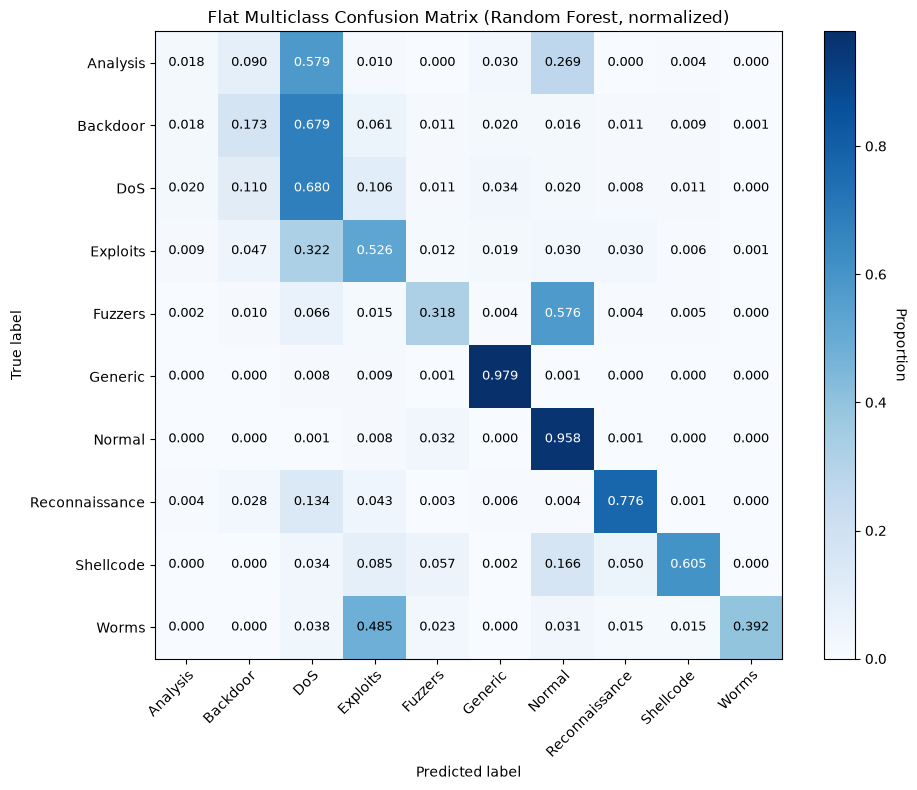

In [120]:
# Definimos una función para generar la matriz de confusión
def plot_confusion_matrix_pretty(
    cm,
    labels,
    title="Confusion Matrix",
    cmap="Blues",
    figsize=(10, 8),
    normalize=False,
    savepath=None
):
    """
    Matriz de confusión atractiva con anotaciones.
    Opcionalmente, normalizar por recuentos de clases reales.
    """

    # Normalizamos la matriz de confusión si es necesario
    if normalize:
            cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
            cm_display = np.round(cm, 3)
    else:
        cm_display = cm

    # Creamos la figura 
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm_display, interpolation="nearest", cmap=cmap) # Mostramos como mapa de calor

    cbar = fig.colorbar(im, ax=ax)  # Barra de color
    cbar.ax.set_ylabel("Count" if not normalize else "Proportion", rotation=270, labelpad=15)

    # Creamos los ejes y etiquetas
    ax.set(
        xticks=np.arange(len(labels)),
        yticks=np.arange(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted label",
        ylabel="True label",
        title=title,
    )

    # Rotamos las etiquetas del eje x
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Añadimos anotaciones en cada celda
    thresh = cm_display.max() / 2.0
    for i in range(cm_display.shape[0]):
        for j in range(cm_display.shape[1]):
            value = cm_display[i, j]
            ax.text(
                j, i,
                f"{value:.0f}" if not normalize else f"{value:.3f}",
                ha="center",
                va="center",
                color="white" if value > thresh else "black",
                fontsize=9
            )

    # Ajustamos el diseño y guardamos la figura si se proporciona una ruta
    ax.grid(False)  # Desactivamos la cuadrícula
    fig.tight_layout()  # Ajustamos el diseño para que no se solapen los elementos
    if savepath is not None:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()

# Generamos la matriz de confusión para el modelo Random Forest multiclase
cm = rf_mc_res["ConfusionMatrix"]
plot_confusion_matrix_pretty(
    cm,
    labels_mc,
    title="Flat Multiclass Confusion Matrix (Random Forest, normalized)",
    cmap="Blues",
    normalize=True,
    savepath="cm_flat_rf.png"
)

* Preparamos un subconjunto "solo ataque", eliminando todas las filas de clase normal y dejando solo las de clase ataque para entrenar y evaluar el modelo.

In [121]:
# Creamos una máscara para identificar los ataques
attack_mask_train = TRAIN_DF[TARGET_MULTI] != "Normal"
attack_mask_test  = TEST_DF[TARGET_MULTI]  != "Normal"

# Conjuntos de entrenamiento y prueba solo con ataques
X_train_attack = X_train[attack_mask_train.values]
X_test_attack  = X_test[attack_mask_test.values]

# Etiquetas multiclase solo con ataques
y_train_attack = y_train_multi[attack_mask_train.values]
y_test_attack  = y_test_multi[attack_mask_test.values]

# Ordenamos las clases de ataques para una mejor visualización
attack_labels = sorted(np.unique(y_train_attack))

# Mostramos un resumen de las etiquetas multiclase solo con ataques
print("Resumen de etiquetas multiclase solo con ataques:")
print("Train:", X_train_attack.shape)
print("Test :", X_test_attack.shape)
print("Classes:", attack_labels)

Resumen de etiquetas multiclase solo con ataques:
Train: (45332, 190)
Test : (119341, 190)
Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']


* Entrenamos y evaluamos un modelo Random Forest solo para conjuntos de ataque.

In [122]:
# Creamos el modelo
rf_attack = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo (multiclase solo con ataques)
rf_attack_res = eval_multiclass(
    rf_attack,
    X_train_attack,
    y_train_attack,
    X_test_attack,
    y_test_attack,
    attack_labels
)

# Mostramos los resultados
print("Random Forest multiclass (solo ataques):")
print("Accuracy :", rf_attack_res["Accuracy"])
print("Macro-F1 :", rf_attack_res["Macro-F1"])
print("Weighted-F1:", rf_attack_res["Weighted-F1"])

Random Forest multiclass (solo ataques):
Accuracy : 0.7613561139926764
Macro-F1 : 0.5569711468173
Weighted-F1: 0.7756604245816975


* Dibujamos la matriz de confusión del modelo anterior ya evaluado, usando las etiquetas de ataque y normalizando los valores para que sea legible.

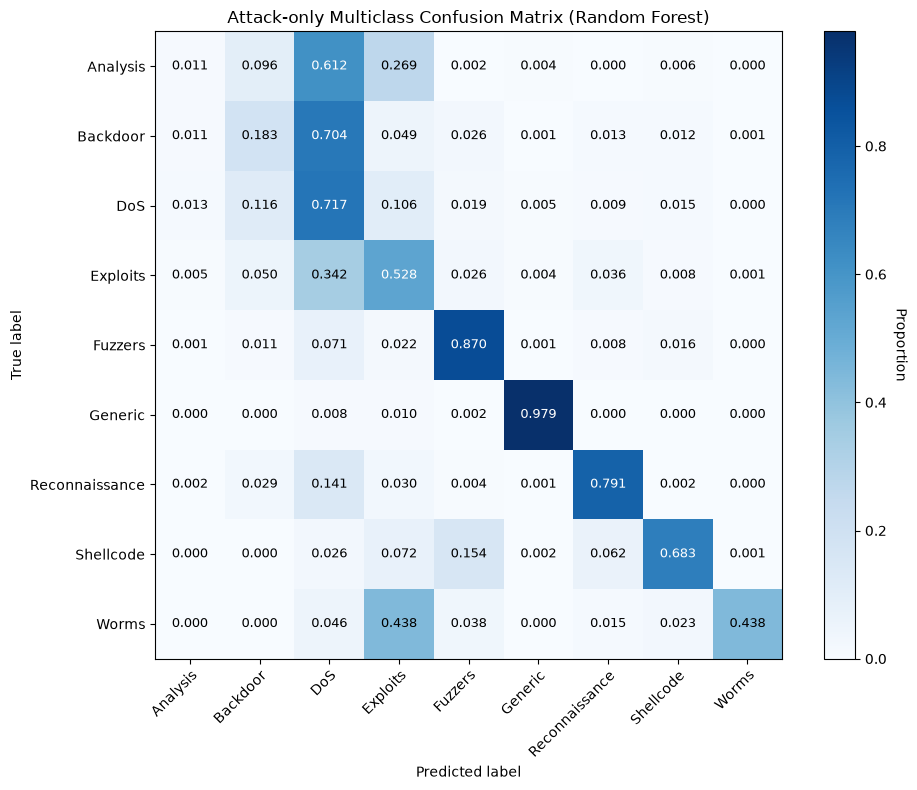

In [123]:
# Definimos la matriz de confusión
plot_confusion_matrix_pretty(
    rf_attack_res["ConfusionMatrix"],
    attack_labels,
    title="Attack-only Multiclass Confusion Matrix (Random Forest)",
    normalize=True,
    savepath="cm_attackonly_rf.png"
)

* Preparamos una versión "agrupada" de las clases. En lugar de clasificar los ataques por categoría (más específica), los reetiquetamos en grupos más amplios. 

In [124]:
# Creamos el diccionario de mapeo de grupos
GROUP_MAP = {
    "Normal": "Normal",
    "Reconnaissance": "Recon",
    "DoS": "DoS",
    "Worms": "DoS",
    "Exploits": "Exploit",
    "Shellcode": "Exploit",
    "Backdoor": "Exploit",
    "Fuzzers": "Fuzzing",
    "Generic": "Generic",
    "Analysis": "Analysis",
}

# Creamos el vector de etiquetas de grupo para el conjunto de entrenamiento y prueba
y_train_group = np.array([GROUP_MAP[y] for y in y_train_multi])
y_test_group  = np.array([GROUP_MAP[y] for y in y_test_multi])

# Ordenamos por grupo para una mejor visualización
group_labels = sorted(np.unique(y_train_group))
print("Grouped labels:", group_labels)

Grouped labels: [np.str_('Analysis'), np.str_('DoS'), np.str_('Exploit'), np.str_('Fuzzing'), np.str_('Generic'), np.str_('Normal'), np.str_('Recon')]


* Entrenamos y evaluamos un modelo Ranfom Forest para conjuntos agrupados.

In [125]:
# Creamos el modelo
rf_group = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo
rf_group_res = eval_multiclass(
    rf_group,
    X_train,
    y_train_group,
    X_test,
    y_test_group,
    group_labels
)

# Mostramos los resultados
print("Random Forest grouped multiclass:")
print("Accuracy :", rf_group_res["Accuracy"])
print("Macro-F1 :", rf_group_res["Macro-F1"])
print("Weighted-F1:", rf_group_res["Weighted-F1"])

Random Forest grouped multiclass:
Accuracy : 0.7619381662018581
Macro-F1 : 0.6044447176827338
Weighted-F1: 0.7580486276465151


* Dibujamos la matriz de confusión del modelo anterior ya evaluado, usando las etiquetas agrupadas y normalizando los valores para que sea legible.

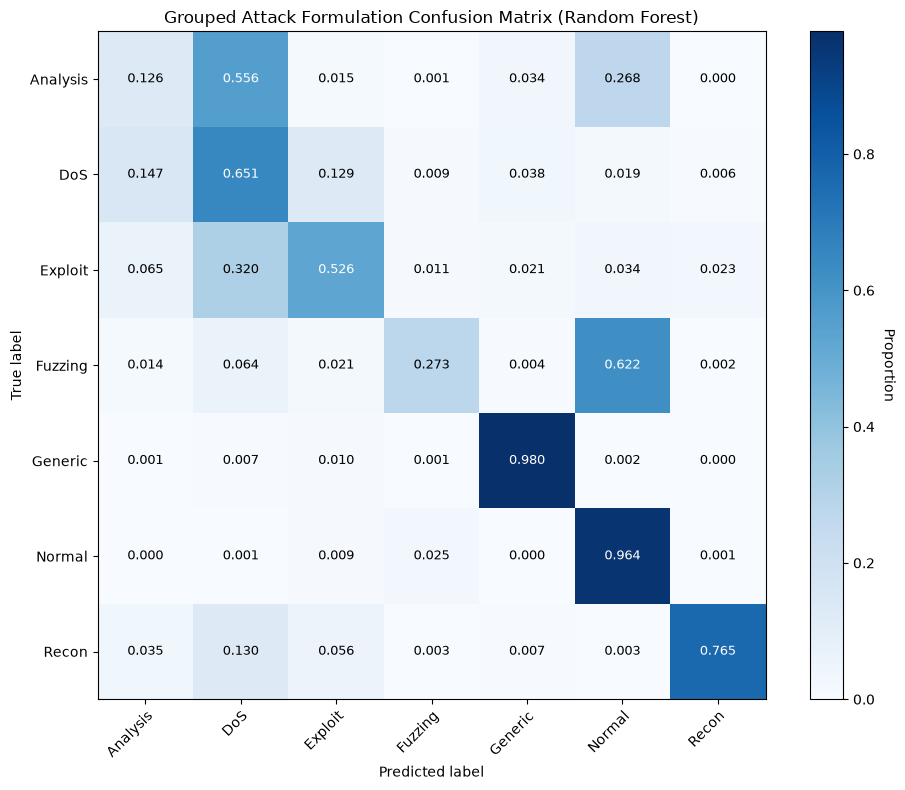

In [126]:
# Definimos la matriz de confusión para el modelo agrupado
plot_confusion_matrix_pretty(
    rf_group_res["ConfusionMatrix"],
    group_labels,
    title="Grouped Attack Formulation Confusion Matrix (Random Forest)",
    normalize=True,
    savepath="cm_grouped_rf"
)

* Entrenamos y evaluamos un modelo de Regresión Logística para conjuntos de solo ataque en problema multiclass.

In [127]:
# Creamos el modelo
lr_attack = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)

# Evaluamos el modelo (multiclase solo con ataques)
lr_attack_res = eval_multiclass(
    lr_attack,
    X_train_attack, y_train_attack,
    X_test_attack,  y_test_attack,
    attack_labels
)

# Mostramos los resultados
print("Logistic Regression multiclass (solo ataques):")
print("Accuracy :", lr_attack_res["Accuracy"])
print("Macro-F1 :", lr_attack_res["Macro-F1"])
print("Weighted-F1:", lr_attack_res["Weighted-F1"])

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression multiclass (solo ataques):
Accuracy : 0.6681526047209257
Macro-F1 : 0.41044722217882545
Weighted-F1: 0.6913890389098425


* Entrenamos y evaluamos un modelo de Regresión Logística para conjuntos agrupados en problema multiclass.

In [128]:
# Creamos el modelo
lr_group = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)

# Evaluamos el modelo 
lr_group_res = eval_multiclass(
    lr_group,
    X_train, y_train_group,
    X_test,  y_test_group,
    group_labels
)

# Mostramos los resultados
print("Logistic Regression grouped multiclass:")
print("Accuracy :", lr_group_res["Accuracy"])
print("Macro-F1 :", lr_group_res["Macro-F1"])
print("Weighted-F1:", lr_group_res["Weighted-F1"])

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression grouped multiclass:
Accuracy : 0.725705910197843
Macro-F1 : 0.563182560635906
Weighted-F1: 0.7311075403044035


* Entrenamos y evaluamos un modelo ExtraTreesClassifier para "flat multiclass" , es decir, los conjuntos originales sin agruparlos ni filtrarlos.

In [129]:
# Importamos la librería necesaria
from sklearn.ensemble import ExtraTreesClassifier

# Creamos el modelo
et_flat = ExtraTreesClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo
et_flat_res = eval_multiclass(
    et_flat,
    X_train,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("Extra Trees multiclass (flat):")
print("Accuracy :", et_flat_res["Accuracy"])
print("Macro-F1 :", et_flat_res["Macro-F1"])
print("Weighted-F1:", et_flat_res["Weighted-F1"])

Extra Trees multiclass (flat):
Accuracy : 0.7435625438431399
Macro-F1 : 0.47310260201135057
Weighted-F1: 0.7202772145000711


* Entrenamos y evaluamos un modelo ExtraTreesClassifier para conjuntos de solo ataque en problema multiclass.

In [130]:
# Creamos el modelo
et_attack = ExtraTreesClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo (multiclase solo con ataques)
et_attack_res = eval_multiclass(
    et_attack,
    X_train_attack,
    y_train_attack,
    X_test_attack,
    y_test_attack,
    attack_labels
)

# Mostramos los resultados
print("Extra Trees multiclass (solo ataques):")
print("Accuracy :", et_attack_res["Accuracy"])
print("Macro-F1 :", et_attack_res["Macro-F1"])
print("Weighted-F1:", et_attack_res["Weighted-F1"])


Extra Trees multiclass (solo ataques):
Accuracy : 0.753764422956067
Macro-F1 : 0.50867475847799
Weighted-F1: 0.7610159504527302


* Entrenamos y evaluamos un modelo ExtraTrees para conjuntos agrupados en problema multiclass.

In [131]:
# Creamos el modelo
et_group = ExtraTreesClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

# Evaluamos el modelo
et_group_res = eval_multiclass(
    et_group,
    X_train,
    y_train_group,
    X_test,
    y_test_group,
    group_labels
)

# Mostramos los resultados
print("Extra Trees grouped multiclass:")
print("Accuracy :", et_group_res["Accuracy"])
print("Macro-F1 :", et_group_res["Macro-F1"])
print("Weighted-F1:", et_group_res["Weighted-F1"])

Extra Trees grouped multiclass:
Accuracy : 0.7461574874102463
Macro-F1 : 0.5678352180391613
Weighted-F1: 0.727330877344923


* Entrenamos y evaluamos un modelo SGD para "flat multiclass", es decir, los conjuntos originales sin agruparlos ni filtrarlos.

In [132]:
# Importamos la librería necesaria
from sklearn.linear_model import SGDClassifier

# Creamos el modelo
sgd_flat = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

# Evaluamos el modelo
sgd_flat_res = eval_multiclass(
    sgd_flat,
    X_train, y_train_multi,
    X_test,  y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("SGD multiclass (flat):")
print("Accuracy :", sgd_flat_res["Accuracy"])
print("Macro-F1 :", sgd_flat_res["Macro-F1"])
print("Weighted-F1:", sgd_flat_res["Weighted-F1"])

SGD multiclass (flat):
Accuracy : 0.70174688179034
Macro-F1 : 0.39819194301336125
Weighted-F1: 0.6910465305998139


* Entrenamos y evaluamos un modelo SGD para conjuntos de solo ataque en el problema multiclass.

In [133]:
# Creamos el modelo
sgd_attack = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

# Evaluamos el modelo (multiclase solo con ataques)
sgd_attack_res = eval_multiclass(
    sgd_attack,
    X_train_attack, y_train_attack,
    X_test_attack,  y_test_attack,
    attack_labels
)

# Mostramos los resultados
print("SGD multiclass (solo ataques):")
print("Accuracy :", sgd_attack_res["Accuracy"])
print("Macro-F1 :", sgd_attack_res["Macro-F1"])
print("Weighted-F1:", sgd_attack_res["Weighted-F1"])

SGD multiclass (solo ataques):
Accuracy : 0.6720154850386707
Macro-F1 : 0.3923116005036641
Weighted-F1: 0.6904624108704019


* Entrenamos y evaluamos un modelo SGD para conjuntos agrupados en el problema multiclass.

In [134]:
# Creamos el modelo
sgd_group = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

# Evaluamos el modelo 
sgd_group_res = eval_multiclass(
    sgd_group,
    X_train, y_train_group,
    X_test,  y_test_group,
    group_labels
)

# Mostramos los resultados
print("SGD grouped multiclass:")
print("Accuracy :", sgd_group_res["Accuracy"])
print("Macro-F1 :", sgd_group_res["Macro-F1"])
print("Weighted-F1:", sgd_group_res["Weighted-F1"])

SGD grouped multiclass:
Accuracy : 0.7215197814544231
Macro-F1 : 0.5377013836503141
Weighted-F1: 0.7098503028502672


* Entrenamos y evaluamos un modelo LinearSVC para "flat multiclass" es decir, los conjuntos originales sin agruparlos ni filtrarlos.

In [135]:
# Importamos la librería necesaria
from sklearn.svm import LinearSVC

# Creamos el modelo
svc_flat = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)

# Evaluamos el modelo
svc_flat_res = eval_multiclass(
    svc_flat,
    X_train, y_train_multi,
    X_test,  y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("Linear SVC multiclass (flat):")  
print("Accuracy :", svc_flat_res["Accuracy"])
print("Macro-F1 :", svc_flat_res["Macro-F1"])
print("Weighted-F1:", svc_flat_res["Weighted-F1"])

Linear SVC multiclass (flat):
Accuracy : 0.7061782469587832
Macro-F1 : 0.4090288160928578
Weighted-F1: 0.7021360967419918


* Entrenamos y evaluamos un modelo LinearSVC para conjuntos de solo ataque en el problema multiclase.

In [136]:
# Creamos el modelo
svc_attack = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)

# Evaluamos el modelo (multiclase solo con ataques)
svc_attack_res = eval_multiclass(
    svc_attack,
    X_train_attack, y_train_attack,
    X_test_attack,  y_test_attack,
    attack_labels
)

# Mostramos los resultados
print("Linear SVC multiclass (solo ataques):")
print("Accuracy :", svc_attack_res["Accuracy"])
print("Macro-F1 :", svc_attack_res["Macro-F1"])
print("Weighted-F1:", svc_attack_res["Weighted-F1"])

Linear SVC multiclass (solo ataques):
Accuracy : 0.6770682330464802
Macro-F1 : 0.40662513225923935
Weighted-F1: 0.6976187331480432


* Entrenamos y evaluamos un modelo LinearSVC para conjuntos agrupados en el problema multiclase.

In [137]:
# Creamos el modelo
svc_group = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)

# Evaluamos el modelo
svc_group_res = eval_multiclass(
    svc_group,
    X_train, y_train_group,
    X_test,  y_test_group,
    group_labels
)

# Mostramos los resultados
print("Linear SVC grouped multiclass:")
print("Accuracy :", svc_group_res["Accuracy"])
print("Macro-F1 :", svc_group_res["Macro-F1"])
print("Weighted-F1:", svc_group_res["Weighted-F1"])

Linear SVC grouped multiclass:
Accuracy : 0.7163926292196349
Macro-F1 : 0.5323167115560553
Weighted-F1: 0.704327375032541


#### RESUMEN FINAL

* Tomamos los resultados calculados de las diferentes configuraciones (flar, attack-only, groupped) para organizarlos en una tabla comparativa y ver como varia el Macro-F1 según el modelo.

In [138]:
# Definimos la función que recibe un diccionario de resultados y devuelve un diccionario con los valores de Accuracy, Macro-F1 y Weighted-F1.
def _pack(res):
    return {
        "Accuracy": float(res["Accuracy"]),
        "Macro-F1": float(res["Macro-F1"]),
        "Weighted-F1": float(res["Weighted-F1"]),
    }

# Creamos una lista vacia para almacenar los resultados de todos los modelos
rows = []

# Añadimos los resultados de cada modelo a la lista
# ---- Flat multiclass
rows.append({"Model": "Logistic Regression", "Task": "Flat", **_pack(lr_mc_res)})
rows.append({"Model": "Random Forest",       "Task": "Flat", **_pack(rf_mc_res)})
rows.append({"Model": "ExtraTrees",          "Task": "Flat", **_pack(et_flat_res)})
rows.append({"Model": "SGD (log_loss)",      "Task": "Flat", **_pack(sgd_flat_res)})
rows.append({"Model": "LinearSVC",           "Task": "Flat", **_pack(svc_flat_res)})

# ---- Attack-only multiclass
rows.append({"Model": "Logistic Regression", "Task": "Attack-only", **_pack(lr_attack_res)})
rows.append({"Model": "Random Forest",       "Task": "Attack-only", **_pack(rf_attack_res)})
rows.append({"Model": "ExtraTrees",          "Task": "Attack-only", **_pack(et_attack_res)})
rows.append({"Model": "SGD (log_loss)",      "Task": "Attack-only", **_pack(sgd_attack_res)})
rows.append({"Model": "LinearSVC",           "Task": "Attack-only", **_pack(svc_attack_res)})

# ---- Grouped formulation
rows.append({"Model": "Logistic Regression", "Task": "Grouped", **_pack(lr_group_res)})
rows.append({"Model": "Random Forest",       "Task": "Grouped", **_pack(rf_group_res)})
rows.append({"Model": "ExtraTrees",          "Task": "Grouped", **_pack(et_group_res)})
rows.append({"Model": "SGD (log_loss)",      "Task": "Grouped", **_pack(sgd_group_res)})
rows.append({"Model": "LinearSVC",           "Task": "Grouped", **_pack(svc_group_res)})

# Creamos un DataFrame con los resultados
summary_long = pd.DataFrame(rows)

# Reorganizamos la tabla para tener como indice "Model", como columnas las tareas (Flat, Attack-Only, Groupped) y los valores Macro-F1
macro_pivot = summary_long.pivot(index="Model", columns="Task", values="Macro-F1")

# Calculamos las diferencias entre agrupada/plana y ataque/plana para ver cuanto mejora o empeora
macro_pivot["Δ(Grouped-Flat)"] = macro_pivot["Grouped"] - macro_pivot["Flat"]
macro_pivot["Δ(AttackOnly-Flat)"] = macro_pivot["Attack-only"] - macro_pivot["Flat"]

# Ordenamos de mayor a menor según la mejora agrupada/plana
macro_pivot_sorted = macro_pivot.sort_values("Δ(Grouped-Flat)", ascending=False)

# Mostramos la tabla ordenada
print("=== Resumen Macro-F1 (mejor a peor) ===")
display(macro_pivot_sorted)

# Creamos una tabla completa con Accuracy, Macro-F1 y Weighted-F1 para cada modelo y tarea
full_pivot = summary_long.pivot_table(  # pivot-table permite agrupar varias métricas a la vez
    index="Model",
    columns="Task",
    values=["Accuracy", "Macro-F1", "Weighted-F1"]
).sort_index(axis=1)    # sort-index ordena columnas de forma consistente

# Mostramos la tabla con todas las métricas
print("\n=== Tabla Full Metrics (opcional) ===")
display(full_pivot)

=== Resumen Macro-F1 (mejor a peor) ===


Task,Attack-only,Flat,Grouped,Δ(Grouped-Flat),Δ(AttackOnly-Flat)
Model,,,,,
SGD (log_loss),0.392312,0.398192,0.537701,0.139509,-0.005880
Logistic Regression,0.410447,0.425633,0.563183,0.137550,-0.015186
LinearSVC,0.406625,0.409029,0.532317,0.123288,-0.002404
ExtraTrees,0.508675,0.473103,0.567835,0.094733,0.035572
Random Forest,0.556971,0.543427,0.604445,0.061018,0.013544



=== Tabla Full Metrics (opcional) ===


Accuracy                        Macro-F1            \
Task                Attack-only      Flat   Grouped Attack-only      Flat   
Model                                                                       
ExtraTrees             0.753764  0.743563  0.746157    0.508675  0.473103   
LinearSVC              0.677068  0.706178  0.716393    0.406625  0.409029   
Logistic Regression    0.668153  0.708716  0.725706    0.410447  0.425633   
Random Forest          0.761356  0.762571  0.761938    0.556971  0.543427   
SGD (log_loss)         0.672015  0.701747  0.721520    0.392312  0.398192   

                              Weighted-F1                      
Task                  Grouped Attack-only      Flat   Grouped  
Model                                                          
ExtraTrees           0.567835    0.761016  0.720277  0.727331  
LinearSVC            0.532317    0.697619  0.702136  0.704327  
Logistic Regression  0.563183    0.691389  0.726648  0.731108  
Random Forest        0.604445    0.775660  0.757734  0.758049  
SGD (log_loss)       0.537701    0.690462  0.691047  0.709850

* Definimos una función auxiliar que implementa una evaluación jerárquica. Primero decidimos si las muestras son "ataque" o "normal", si es ataque se pasa a la segunda etapa, y por último, calcula métricas globales sobre la clasificación final.

In [139]:
# Definimos la función 
def eval_hierarchical(
    bin_model,
    mc_model,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc,
):
    """
    Evaluación jerárquica integral:
    Etapa 1: binaria (ataque vs. normal)
    Etapa 2: multiclase (categorías de ataque, entrenada con datos exclusivos de ataque)
    """

    # ------------------
    # Etapa 1: Binaria
    # ------------------
    bin_model.fit(X_train, y_train_bin)     # Entrenamos el modelo binario con el conjunto completo de entrenamiento
    y_hat_bin = bin_model.predict(X_test)   # Predicción binariapara cada muestra del test

    # ------------------
    # Etapa 2: Multiclase (entrenamiento solo ataque)
    # ------------------
    attack_train_mask = (y_train_bin == 1)              # Máscara booleana para las muestras

    # Filtramos características y etiquetas
    X_train_attack = X_train[attack_train_mask]         # Muestras entrenamiento que son ataques
    y_train_attack = y_train_multi[attack_train_mask]   # Clases reales de ataque para esas muestras

    mc_model.fit(X_train_attack, y_train_attack)        # Entrenamos el modelo multiclasificado usando solo muestras de ataque del conjunto de entrenamiento

    # ------------------
    # Predicción extremo a extremo
    # ------------------
    y_hat_final = np.array(["Normal"] * len(y_test_multi), dtype=object)    # Array de predicciones finales (valor por defecto = Normal)
    
    attack_idx = np.where(y_hat_bin == 1)[0]    # Busca los indicen del test predichos como ataque por el primer modelo
    if len(attack_idx) > 0:     # Si hay alguna muestra predicha como ataque
        y_hat_attack = mc_model.predict(X_test[attack_idx])     # Usamos el modelo multiclasificador para predecir el tipo concreto de ataque
        y_hat_final[attack_idx] = y_hat_attack                  # Sustituimos y_hat_attack en las posiciones correspondientes

    # ------------------
    # Métricas
    # ------------------
    out = {     # Calculamos las métricas finales del sistema jerárquico
        "Accuracy": accuracy_score(y_test_multi, y_hat_final),
        "Macro-F1": f1_score(y_test_multi, y_hat_final, average="macro"),
        "Weighted-F1": f1_score(y_test_multi, y_hat_final, average="weighted"),
        "ConfusionMatrix": confusion_matrix(y_test_multi, y_hat_final, labels=labels_mc),
        "ReportDict": classification_report(
            y_test_multi,
            y_hat_final,
            output_dict=True,
            zero_division=0
        ),
        "Pred": y_hat_final
    }

    # Devolvemos las métricas calculadas
    return out

* Entrenamos y evaluamos un modelo jerárquico basado en Random Forest para resolver el problema en dos etapas. Primero clasificar en "Nomral" o "Ataque", si predice ataque identificar el tipo concreto de ataque. Finalmente se mide la calidad del sistema completo.

In [140]:
# Creamos el modelo binario
rf_bin = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

# Creamos el modelo multiclase
rf_mc = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

# Usamos la evaluación jerárquica definida en la celda anterior
rf_hier_res = eval_hierarchical(
    rf_bin,
    rf_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("Random Forest Jerárquico:")
print("Accuracy :", rf_hier_res["Accuracy"])
print("Macro-F1 :", rf_hier_res["Macro-F1"])
print("Weighted-F1:", rf_hier_res["Weighted-F1"])

Random Forest Jerárquico:
Accuracy : 0.7503436161536663
Macro-F1 : 0.5219946433282405
Weighted-F1: 0.7338120183200201


* Entrenamos y evaluamos un modelo jerárquico basado en Extra Trees para resolver el problema en dos etapas. Primero clasificar en "Nomral" o "Ataque", si predice ataque identificar el tipo concreto de ataque. Finalmente se mide la calidad del sistema completo.

In [141]:
# Creamos el modelo binario
et_bin = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

# Creamos el modelo multiclase
et_mc = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

# Usamos la evaluación jerárquica definida anteriormente
et_hier_res = eval_hierarchical(
    et_bin,
    et_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("ExtraTrees jerárquico:")
print("Accuracy :", et_hier_res["Accuracy"])
print("Macro-F1 :", et_hier_res["Macro-F1"])
print("Weighted-F1:", et_hier_res["Weighted-F1"])

ExtraTrees jerárquico:
Accuracy : 0.7457582653229992
Macro-F1 : 0.4762838553137452
Weighted-F1: 0.7253885096513394


* Entrenamos y evaluamos un modelo jerárquico basado en Logistic Regression para resolver el problema en dos etapas. Primero clasificar en "Nomral" o "Ataque", si predice ataque identificar el tipo concreto de ataque. Finalmente se mide la calidad del sistema completo.

In [142]:
# Creamos el modelo binario
lr_bin = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

# Creamos el modelo multiclase
lr_mc = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

# Usamos la evaluación jerárquica definida anteriormente
lr_hier_res = eval_hierarchical(
    lr_bin,
    lr_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("Logistic Regression jerárquico:")
print("Accuracy :", lr_hier_res["Accuracy"])
print("Macro-F1 :", lr_hier_res["Macro-F1"])
print("Weighted-F1:", lr_hier_res["Weighted-F1"])

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression jerárquico:
Accuracy : 0.6883102069681364
Macro-F1 : 0.3859756534554019
Weighted-F1: 0.6643482501776108


* Entrenamos y evaluamos un modelo jerárquico basado en LinearSVC para resolver el problema en dos etapas. Primero clasificar en "Nomral" o "Ataque", si predice ataque identificar el tipo concreto de ataque. Finalmente se mide la calidad del sistema completo.

In [143]:
# Creamos el modelo binario
svc_bin = LinearSVC(
    class_weight="balanced",
    random_state=SEED
)

# Creamos el modelo multiclase
svc_mc = LinearSVC(
    class_weight="balanced",
    random_state=SEED
)

# Usamos la evaluación jerárquica definida anteriormente
svc_hier_res = eval_hierarchical(
    svc_bin,
    svc_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("LinearSVC jerárquico:")
print("Accuracy :", svc_hier_res["Accuracy"])
print("Macro-F1 :", svc_hier_res["Macro-F1"])
print("Weighted-F1:", svc_hier_res["Weighted-F1"])

LinearSVC jerárquico:
Accuracy : 0.6834511038490713
Macro-F1 : 0.36131260248907726
Weighted-F1: 0.6564938733129196


* Entrenamos y evaluamos un modelo jerárquico basado en SGDClassifier para resolver el problema en dos etapas. Primero clasificar en "Nomral" o "Ataque", si predice ataque identificar el tipo concreto de ataque. Finalmente se mide la calidad del sistema completo.

In [144]:
# Creamos el modelo binario
sgd_bin = SGDClassifier(
    loss="log_loss",
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

# Creamos el modelo multiclase
sgd_mc = SGDClassifier(
    loss="log_loss",
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

# Usamos la evaluación jerárquica definida anteriormente
sgd_hier_res = eval_hierarchical(
    sgd_bin,
    sgd_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

# Mostramos los resultados
print("SGD jerárquico:")
print("Accuracy :", sgd_hier_res["Accuracy"])
print("Macro-F1 :", sgd_hier_res["Macro-F1"])
print("Weighted-F1:", sgd_hier_res["Weighted-F1"])

SGD jerárquico:
Accuracy : 0.6838731386270183
Macro-F1 : 0.35713241072872015
Weighted-F1: 0.6623346005855681


* Construimos una tabla comparativa de los resultados de todos los modelos de clasificación jerárquica. Identificando primero si es ataque o no y después el tipo de ataque.

In [145]:
# Definimos una función que recibe un diccionario de resultados y devuelve un diccionario con los valores de Accuracy, Macro-F1 y Weighted-F1.
def _pack_mc(res):
    return {
        "Accuracy": float(res["Accuracy"]),
        "Macro-F1": float(res["Macro-F1"]),
        "Weighted-F1": float(res["Weighted-F1"]),
    }

# Creamos una lista en la cual cada elemento representa cada uno de los modelos
rows = [
    {"Model": "Random Forest",       **_pack_mc(rf_hier_res)},
    {"Model": "ExtraTrees",          **_pack_mc(et_hier_res)},
    {"Model": "Logistic Regression", **_pack_mc(lr_hier_res)},
    {"Model": "Linear SVM",          **_pack_mc(svc_hier_res)},
    {"Model": "SGD (log_loss)",      **_pack_mc(sgd_hier_res)},
]

# Convertimos la lista en un DataFrame y mostramos los resultados
hier_table = pd.DataFrame(rows).set_index("Model").sort_values("Macro-F1", ascending=False)

print("=== Resultados Jerárquicos (binary → attack attribution) ===")
display(hier_table)

# OPCIONAL: Exportamos a LaTeX (para copiar directamente los resultados dentro de Overleaf)
print("\n--- LaTeX (redondeo de 3 decimales) ---")
print(hier_table.round(3).to_latex(
    index=True,
    escape=False,
    column_format="lccc"
))

=== Resultados Jerárquicos (binary → attack attribution) ===


,Accuracy,Macro-F1,Weighted-F1
Model,,,
Random Forest,0.750344,0.521995,0.733812
ExtraTrees,0.745758,0.476284,0.725389
Logistic Regression,0.688310,0.385976,0.664348
Linear SVM,0.683451,0.361313,0.656494
SGD (log_loss),0.683873,0.357132,0.662335



--- LaTeX (redondeo de 3 decimales) ---
\begin{tabular}{lccc}
\toprule
 & Accuracy & Macro-F1 & Weighted-F1 \\
Model &  &  &  \\
\midrule
Random Forest & 0.750000 & 0.522000 & 0.734000 \\
ExtraTrees & 0.746000 & 0.476000 & 0.725000 \\
Logistic Regression & 0.688000 & 0.386000 & 0.664000 \\
Linear SVM & 0.683000 & 0.361000 & 0.656000 \\
SGD (log_loss) & 0.684000 & 0.357000 & 0.662000 \\
\bottomrule
\end{tabular}



* Creamos una tabla resumen final quecompara el rendimiento de varios modelos en las 4 formulaciones del problema estudiadas (flat, hierarchical, attacks-only, groupped). Calculamos las diferencias de rendimiento respecto a la formulación base (flat) y las ordenamos respecto la mejore en grouped.

In [146]:
# Creamos una lista vacía para guardar los datos de cada modelo
rows = []

# Definimos una función que almacena el nombre del modelo y el resultado de sus cuatro formulaciones en cada fila de la lista 
def add_row(model, flat, hier, attack, grouped):
    rows.append({
        "Model": model,
        "Flat": flat["Macro-F1"],
        "Hierarchical": hier["Macro-F1"],
        "Attack-only": attack["Macro-F1"],
        "Grouped": grouped["Macro-F1"],
    })

# Llamamos a la función anterior para cada uno de los modelos y así ir añadiendo los resultados a la lista
add_row("Random Forest", rf_mc_res, rf_hier_res, rf_attack_res, rf_group_res)
add_row("ExtraTrees", et_flat_res, et_hier_res, et_attack_res, et_group_res)
add_row("Logistic Regression", lr_mc_res, lr_hier_res, lr_attack_res, lr_group_res)
add_row("Linear SVM", svc_flat_res, svc_hier_res, svc_attack_res, svc_group_res)
add_row("SGD (log_loss)", sgd_flat_res, sgd_hier_res, sgd_attack_res, sgd_group_res)

# Convertimos la lista en un DataFrame
df_macro = pd.DataFrame(rows).set_index("Model")

# Calculamos las diferencias deltas (mejora o empeora)
df_macro["Δ(Grouped–Flat)"] = df_macro["Grouped"] - df_macro["Flat"]
df_macro["Δ(Hierarchical–Flat)"] = df_macro["Hierarchical"] - df_macro["Flat"]

# Ordenamos de mayor a menor según Δ(Grouped–Flat) y mostramos
df_macro_sorted = df_macro.sort_values("Δ(Grouped–Flat)", ascending=False)

print("=== Macro-F1 de todas las formulaciones (mayor a menor) ===")
display(df_macro_sorted.round(3))

#  OPCIONAL: Exportamos a LaTeX (para copiar directamente los resultados dentro de Overleaf
print("\n--- LaTeX (redondeo de 3 decimales) ---")
print(
    df_macro_sorted.round(3).to_latex(
        index=True,
        escape=False,
        column_format="lcccccc"
    )
)

=== Macro-F1 de todas las formulaciones (mayor a menor) ===


,Flat,Hierarchical,Attack-only,Grouped,Δ(Grouped–Flat),Δ(Hierarchical–Flat)
Model,,,,,,
SGD (log_loss),0.398,0.357,0.392,0.538,0.140,-0.041
Logistic Regression,0.426,0.386,0.410,0.563,0.138,-0.040
Linear SVM,0.409,0.361,0.407,0.532,0.123,-0.048
ExtraTrees,0.473,0.476,0.509,0.568,0.095,0.003
Random Forest,0.543,0.522,0.557,0.604,0.061,-0.021



--- LaTeX (redondeo de 3 decimales) ---
\begin{tabular}{lcccccc}
\toprule
 & Flat & Hierarchical & Attack-only & Grouped & Δ(Grouped–Flat) & Δ(Hierarchical–Flat) \\
Model &  &  &  &  &  &  \\
\midrule
SGD (log_loss) & 0.398000 & 0.357000 & 0.392000 & 0.538000 & 0.140000 & -0.041000 \\
Logistic Regression & 0.426000 & 0.386000 & 0.410000 & 0.563000 & 0.138000 & -0.040000 \\
Linear SVM & 0.409000 & 0.361000 & 0.407000 & 0.532000 & 0.123000 & -0.048000 \\
ExtraTrees & 0.473000 & 0.476000 & 0.509000 & 0.568000 & 0.095000 & 0.003000 \\
Random Forest & 0.543000 & 0.522000 & 0.557000 & 0.604000 & 0.061000 & -0.021000 \\
\bottomrule
\end{tabular}



* Por último, creamos un gráfico de barras que resume, para cada formulación, el valor medio de Macro-F1 y la variabilidad entre los diferentes modelos. De esta forma visualizamos de forma clara si una formulación mejora el rendimiento promedio y con que estabilidad.

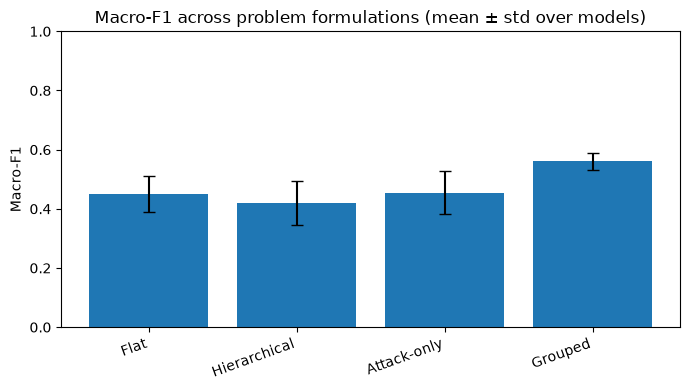

In [147]:
# Indicamos las columnas, calculamos la media de Macro-F1 para cada uno de ellas y su desviación estábdar
cols = ["Flat", "Hierarchical", "Attack-only", "Grouped"]
means = df_macro[cols].mean()
stds  = df_macro[cols].std()

# Preparamos la figura
plt.figure(figsize=(7, 4))                                                  # Tamaño de la figura
plt.bar(means.index, means.values, yerr=stds.values, capsize=4)             # Dibujo de las barras
plt.ylabel("Macro-F1")                                                      # Etiqueta eje Y
plt.ylim(0, 1.0)                                                            # Límite vertical
plt.xticks(rotation=20, ha="right")                                         # Rotación etiquetas
plt.title("Macro-F1 across problem formulations (mean ± std over models)")  # Título gráfico
plt.tight_layout()                                                          # Ajuste vertical

# Guardamos la figura y mostramos
plt.savefig("macro_f1_by_formulation.png", dpi=300, bbox_inches="tight")
plt.show()

Entrenar un MLP con dos capas ocultas. Implementar inferencia

MLP -> scikit learn
mlp en python torch

Implementar inferencia en triton

Comparar velocidad y consumo de memoria de `pytoch y su version usando torch.compile

# RED NEURONAL MLP CON SCIKIT-LEARN

* En esta sección vamos a implementar un perceptrón multicapa (MLP). En la primera implementación utilizaremos la formulación agrupada ( ya que hemos visto que es la que ofrece mejor rendimiento respecto al resto). 

In [148]:
# Importamos la librería necesaria
from sklearn.neural_network import MLPClassifier

# Configuración de la red neuronal (hiperparámetros)
MLP_HIDDEN_LAYERS = (128, 64)
MLP_ACTIVATION = "relu"
MLP_SOLVER = "adam"
MLP_ALPHA = 1e-4
MLP_BATCH_SIZE = 256
MLP_LEARNING_RATE = 1e-3
MLP_MAX_ITER = 100
MLP_VALIDATION_FRACTION = 0.1
MLP_N_ITER_NO_CHANGE = 10

* Entrenamos y evaluamos un modelo MLPClassifier para conjuntos agrupados en el problema multiclase.

In [149]:
# Creamos el modelo 
mlp_group = MLPClassifier(
    hidden_layer_sizes=MLP_HIDDEN_LAYERS,
    activation=MLP_ACTIVATION,
    solver=MLP_SOLVER,
    alpha=MLP_ALPHA,
    batch_size=MLP_BATCH_SIZE,
    learning_rate_init=MLP_LEARNING_RATE,
    max_iter=MLP_MAX_ITER,
    early_stopping=False,
    validation_fraction=MLP_VALIDATION_FRACTION,
    n_iter_no_change=MLP_N_ITER_NO_CHANGE,
    random_state=SEED
)

# Entrenamos el modelo con el conjunto de entrenamiento
mlp_group.fit(X_train, y_train_group)
print("Entrenamiento completado.")
print("Iteraciones:", mlp_group.n_iter_)
print("Loss final:", mlp_group.loss_)

# Evaluamos el modelo
mlp_group_res = eval_multiclass(
    mlp_group,
    X_train,
    y_train_group,
    X_test,
    y_test_group,
    group_labels
)

# Mostramos los resultados
print("MLP grouped multiclass:")
print("Accuracy :", mlp_group_res["Accuracy"])
print("Macro-F1 :", mlp_group_res["Macro-F1"])
print("Weighted-F1:", mlp_group_res["Weighted-F1"])

# Mostramos el informe de clasificación para el modelo MLP agrupado 
print("\nClassification Report:")
print(
    classification_report(
        y_test_group,
        mlp_group_res["Pred"],
        labels=group_labels,
        zero_division=0
    )
)

# Mostramos la matriz de confusión para el modelo MLP agrupado
mlp_group_res["ConfusionMatrix"]

# Mostramos la curva de aprendizaje del modelo MLP agrupado
mlp_group.loss_curve_

/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Entrenamiento completado.
Iteraciones: 100
Loss final: 0.27505024708062403


/home/rober/tfg-unsw-nb15/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP grouped multiclass:
Accuracy : 0.7522941012085023
Macro-F1 : 0.540605482662915
Weighted-F1: 0.720530931655704

Classification Report:
              precision    recall  f1-score   support

    Analysis       0.00      0.00      0.00      2000
         DoS       0.34      0.56      0.42     12394
     Exploit       0.74      0.61      0.67     36272
     Fuzzing       0.72      0.07      0.13     18184
     Generic       0.98      0.98      0.98     40000
      Normal       0.74      0.98      0.85     56000
       Recon       0.81      0.66      0.73     10491

    accuracy                           0.75    175341
   macro avg       0.62      0.55      0.54    175341
weighted avg       0.76      0.75      0.72    175341



[np.float64(0.6663250492442052),
 np.float64(0.4565743740363566),
 np.float64(0.42122627272320706),
 np.float64(0.4046549519721556),
 np.float64(0.39196772207915187),
 np.float64(0.38272430778043365),
 np.float64(0.3741439110592223),
 np.float64(0.36587615122129985),
 np.float64(0.3612383540757016),
 np.float64(0.356553787680325),
 np.float64(0.3525975172913135),
 np.float64(0.3513393270708697),
 np.float64(0.3461402368697095),
 np.float64(0.3409477380322962),
 np.float64(0.337807509442135),
 np.float64(0.33543276152113927),
 np.float64(0.33147745862682587),
 np.float64(0.32918260255465476),
 np.float64(0.3285257068319077),
 np.float64(0.32597927992826603),
 np.float64(0.3230001033119118),
 np.float64(0.321321883115175),
 np.float64(0.320751427750056),
 np.float64(0.3186771974965595),
 np.float64(0.3168058484308191),
 np.float64(0.31399370688864403),
 np.float64(0.3140763324129773),
 np.float64(0.31200865210513506),
 np.float64(0.3117600187556584),
 np.float64(0.3104997316899752),
 np.

* Creamos una tabla para comparar los resultados de los modelos implementados anteriormente con el modelo MLP nuevamente implementado.

In [150]:
# Comparación de resultados — modelos anteriores vs MLP
comparison_grouped = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Extra Trees",
        "Logistic Regression",
        "Linear SVM",
        "SGD",
        "MLP"
    ],
    "Accuracy": [
        rf_group_res["Accuracy"],
        et_group_res["Accuracy"],
        lr_group_res["Accuracy"],
        svc_group_res["Accuracy"],
        sgd_group_res["Accuracy"],
        mlp_group_res["Accuracy"]
    ],
    "Macro-F1": [
        rf_group_res["Macro-F1"],
        et_group_res["Macro-F1"],
        lr_group_res["Macro-F1"],
        svc_group_res["Macro-F1"],
        sgd_group_res["Macro-F1"],
        mlp_group_res["Macro-F1"]
    ],
    "Weighted-F1": [
        rf_group_res["Weighted-F1"],
        et_group_res["Weighted-F1"],
        lr_group_res["Weighted-F1"],
        svc_group_res["Weighted-F1"],
        sgd_group_res["Weighted-F1"],
        mlp_group_res["Weighted-F1"]
    ]
})

# Ordenar por Macro-F1 descendente
comparison_grouped = comparison_grouped.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

# Mostrar resultados
comparison_grouped.style.format({
    "Accuracy": "{:.4f}",
    "Macro-F1": "{:.4f}",
    "Weighted-F1": "{:.4f}"
})

,Modelo,Accuracy,Macro-F1,Weighted-F1
0,Random Forest,0.7619,0.6044,0.7580
1,Extra Trees,0.7462,0.5678,0.7273
2,Logistic Regression,0.7257,0.5632,0.7311
3,MLP,0.7523,0.5406,0.7205
4,SGD,0.7215,0.5377,0.7099
5,Linear SVM,0.7164,0.5323,0.7043


In [151]:
# El MLP base implementado con Scikit-learn, utilizando una arquitectura 190 → 128 → 64 → 7 y los hiperparámetros establecidos,
# obtiene una Accuracy del 75.28 % y un Macro-F1 de 0.5407. En esta configuración, no supera al Random Forest, que obtiene un Macro-F1 de 0.5702.

### Implementación del MLP con PyTorch

* En este segundo apartado vamos a reimplementar el MLP con PyTroch manteniendo la estructura utilizada en Scikit-learn.

In [152]:
# Realizamos toda la importación necesaria para la implementación del MLP con PyTorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Comprobamos el dispositivo disponible (GPU si está disponible, de lo contrario CPU)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo utilizado:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo utilizado: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


* Dado que PyTorch necesita recibir las etiquetas como indices, usaremos LabelEncoder para convertirlas.

In [153]:
# Codificación de las etiquetas
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train_group)
y_test_encoded = label_encoder.transform(y_test_group)

print("Clases:")
for i, clase in enumerate(label_encoder.classes_):
    print(f"{i}: {clase}")

Clases:
0: Analysis
1: DoS
2: Exploit
3: Fuzzing
4: Generic
5: Normal
6: Recon


* Convertimos los datos a tensores para verificar que PyTorch está recibiendo exactamente los 190 atributos que se esperaban.

In [154]:
# Conversión de los datos a tensores PyTorch
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_encoded,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test_encoded,
    dtype=torch.long
)

print("X_train:", X_train_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([82332, 190])
X_test: torch.Size([175341, 190])
y_train: torch.Size([82332])
y_test: torch.Size([175341])


* Creamos los DataLoader dividiendo los datos por lotes (batches), utilizando el mismo tamaño establecido para el MLP de Scikit-learn.

In [155]:
# Indicamos el tamaño del batch y el número de épocas
BATCH_SIZE = 256

# Creamos los datasets y dataloaders para entrenamiento y prueba
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Número de batches de entrenamiento:", len(train_loader))
print("Número de batches de test:", len(test_loader))

Número de batches de entrenamiento: 322
Número de batches de test: 685


* Definimos la arquitectura que tendrá el MLP.

In [156]:
# Arquitectura de la red neuronal
class MLP(nn.Module):

    def __init__(self, input_size=190, num_classes=7):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Una vez definida la arquitectura, creamos una instancia del modelo
mlp_torch = MLP(
    input_size=190,
    num_classes=7
).to(device)

print(mlp_torch)

MLP(
  (network): Sequential(
    (0): Linear(in_features=190, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=7, bias=True)
  )
)


* Creamos la función de pérdida y el optimizador.

In [157]:
# Configuración del entrenamiento
LEARNING_RATE = 1e-3
NUM_EPOCHS = 100

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    mlp_torch.parameters(),
    lr=LEARNING_RATE
)

* Ahora en PyTroch vamos a implementar explícitamente en el entrenamiento (a diferencia de scikit-learn).

In [158]:
# Entrenamiento del MLP
train_losses = []

print("Comenzando entrenamiento...")

for epoch in range(NUM_EPOCHS):

    mlp_torch.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Reiniciar gradientes
        optimizer.zero_grad()

        # Forward
        outputs = mlp_torch(X_batch)

        # Cálculo de pérdida
        loss = criterion(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Actualización de pesos
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(
        f"Época [{epoch + 1}/{NUM_EPOCHS}] "
        f"- Loss: {epoch_loss:.6f}"
    )

print("Entrenamiento completado.")

Comenzando entrenamiento...
Época [1/100] - Loss: 0.722135
Época [2/100] - Loss: 0.461702
Época [3/100] - Loss: 0.421552
Época [4/100] - Loss: 0.403934
Época [5/100] - Loss: 0.392933
Época [6/100] - Loss: 0.384820
Época [7/100] - Loss: 0.375962
Época [8/100] - Loss: 0.367553
Época [9/100] - Loss: 0.362980
Época [10/100] - Loss: 0.356668
Época [11/100] - Loss: 0.351518
Época [12/100] - Loss: 0.349392
Época [13/100] - Loss: 0.344577
Época [14/100] - Loss: 0.340597
Época [15/100] - Loss: 0.338303
Época [16/100] - Loss: 0.336321
Época [17/100] - Loss: 0.332394
Época [18/100] - Loss: 0.331283
Época [19/100] - Loss: 0.328816
Época [20/100] - Loss: 0.326860
Época [21/100] - Loss: 0.323967
Época [22/100] - Loss: 0.323662
Época [23/100] - Loss: 0.321181
Época [24/100] - Loss: 0.321822
Época [25/100] - Loss: 0.318986
Época [26/100] - Loss: 0.317458
Época [27/100] - Loss: 0.315923
Época [28/100] - Loss: 0.314862
Época [29/100] - Loss: 0.313838
Época [30/100] - Loss: 0.312556
Época [31/100] - Loss

* Ahora evaluaremos el modelo generando las predicciones sobre el conjunto test.

In [159]:
# Evaluación del MLP con PyTorch
mlp_torch.eval()

# Creamos listas para almacenar las predicciones y los objetivos reales
all_predictions = []
all_targets = []

# Evaluamos el modelo en el conjunto de datos de prueba
with torch.no_grad():
    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = mlp_torch(X_batch)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            y_batch.numpy()
        )

y_pred_torch = np.array(all_predictions)
y_true_torch = np.array(all_targets)


# Calculamos las métricas de evaluación
accuracy_torch = accuracy_score(
    y_true_torch,
    y_pred_torch
)

macro_f1_torch = f1_score(
    y_true_torch,
    y_pred_torch,
    average="macro"
)

weighted_f1_torch = f1_score(
    y_true_torch,
    y_pred_torch,
    average="weighted"
)

# Mostramos los resultados
print("MLP PyTorch")
print(f"Accuracy:    {accuracy_torch:.4f}")
print(f"Macro-F1:    {macro_f1_torch:.4f}")
print(f"Weighted-F1: {weighted_f1_torch:.4f}")

MLP PyTorch
Accuracy:    0.7525
Macro-F1:    0.5500
Weighted-F1: 0.7257


* Realizamos el informe de clasificación y la matriz de confusión para el modelo MLP de PyTorch.

In [160]:
# Informe de clasificación
print("\nClassification Report:\n")

print(
    classification_report(
        y_true_torch,
        y_pred_torch,
        target_names=label_encoder.classes_
    )
)

# Matriz de confusión
cm_torch = confusion_matrix(
    y_true_torch,
    y_pred_torch
)

cm_torch


Classification Report:

              precision    recall  f1-score   support

    Analysis       0.00      0.00      0.00      2000
         DoS       0.34      0.70      0.46     12394
     Exploit       0.76      0.58      0.66     36272
     Fuzzing       0.66      0.09      0.16     18184
     Generic       0.98      0.98      0.98     40000
      Normal       0.76      0.98      0.85     56000
       Recon       0.90      0.62      0.74     10491

    accuracy                           0.75    175341
   macro avg       0.63      0.56      0.55    175341
weighted avg       0.77      0.75      0.73    175341



array([[    0,  1255,   251,     1,    20,   472,     1],
       [    0,  8710,  3028,    27,   198,   366,    65],
       [    1, 12345, 21044,   202,   508,  1774,   398],
       [    0,  1267,   914,  1692,    46, 14133,   132],
       [    0,   297,   294,    12, 39311,    74,    12],
       [    1,   116,   538,   572,     8, 54685,    80],
       [    0,  1520,  1530,    50,    33,   858,  6500]])

* Guardamos los resultados obtenidos del modelo siguiendo la estructura que se ha utilizado en los modelos anteriores para añadirlos posteriormente a la tabla sin modificar la lógica de evaluación.

In [161]:
mlp_torch_res = {
    "Accuracy": accuracy_torch,
    "Macro-F1": macro_f1_torch,
    "Weighted-F1": weighted_f1_torch,
    "ConfusionMatrix": cm_torch
}

* Generamos la curva de aprendizaje ya que PyTorch nos proporciona la pérdida de cada epoch.

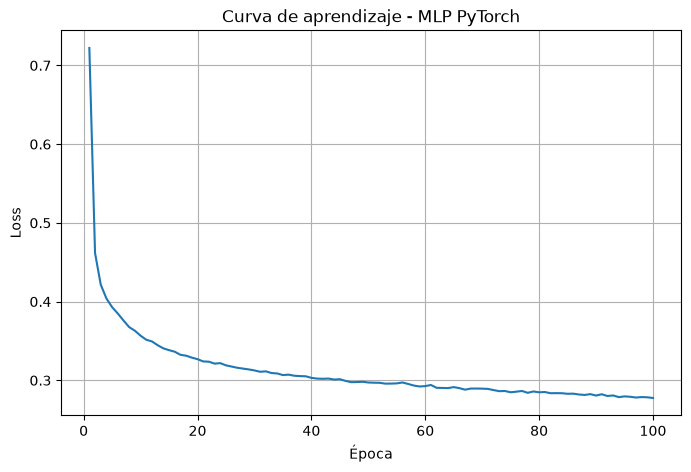

In [162]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses
)

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Curva de aprendizaje - MLP PyTorch")
plt.grid(True)

# Guardamos la figura y mostramos
plt.savefig("mlp_pytorch_learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()

* Por último, realizamos la comparación del MLP entre los modelos de scikit-learn y PyTorch.

In [163]:
comparison_mlp = pd.DataFrame({
    "Modelo": [
        "MLP Scikit-learn",
        "MLP PyTorch"
    ],
    "Accuracy": [
        mlp_group_res["Accuracy"],
        mlp_torch_res["Accuracy"]
    ],
    "Macro-F1": [
        mlp_group_res["Macro-F1"],
        mlp_torch_res["Macro-F1"]
    ],
    "Weighted-F1": [
        mlp_group_res["Weighted-F1"],
        mlp_torch_res["Weighted-F1"]
    ]
})

comparison_mlp.style.format({
    "Accuracy": "{:.4f}",
    "Macro-F1": "{:.4f}",
    "Weighted-F1": "{:.4f}"
})

,Modelo,Accuracy,Macro-F1,Weighted-F1
0,MLP Scikit-learn,0.7523,0.5406,0.7205
1,MLP PyTorch,0.7525,0.5500,0.7257


### Benchmark de inferencia del MLP con PyTorch


* Mediremos el modelo ya entrenado usando lotes de 256 registros y mediremos el tiempo que tarde el modelo en realizar la inferencia repetidamente sobre el mismo lote.

In [164]:
# Realizamos las importaciones necesarias
import time
import platform
import statistics

# Mostramos las versiones y el dispositivo utilizado
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU CUDA no disponible; se utilizará CPU.")

Python: 3.12.3
PyTorch: 2.15.0+cu132
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


* Preparamos el modelo y los datos (lotes de 256 registros) para la inferencia.

In [165]:
# Preparamos el modelo
mlp_torch.eval()

# Preparamos los datos
BENCHMARK_BATCH_SIZE = 256
WARMUP_ITERATIONS = 20
BENCHMARK_ITERATIONS = 200
BENCHMARK_REPEATS = 5

# Seleccionamos un lote de test y lo llevamos al dispositivo
X_benchmark = X_test_tensor[:BENCHMARK_BATCH_SIZE].to(device)
assert X_benchmark.shape == (BENCHMARK_BATCH_SIZE, 190)

# Imprimimos información sobre el tamaño del lote y el modo de evaluación
print("Tamaño del lote:", X_benchmark.shape)
print("Modo de evaluación:", not mlp_torch.training)

Tamaño del lote: torch.Size([256, 190])
Modo de evaluación: True


* Creamos una función para medir la latencia, el throughput y la desviación.

In [166]:
# Definimos la función para medir el tiempo de inferencia
def benchmark_inference(
        model,
        inputs,
        warmup_iterations=20,
        iterations=200,
        repeats=5
):
    model.eval()  # Aseguramos que el modelo esté en modo evaluación

    # Definimos una subfnción para sincronizar la GPU si está disponible (esperamos a que todas las ejecuciones de CUDA finalicen antes de medir el tiempo)
    def synchronize():
        if inputs.device.type == "cuda":
            torch.cuda.synchronize(inputs.device)

    # Excluimos las ejecuciones de calentamiento de la medición
    with torch.inference_mode():
        for _ in range(warmup_iterations):
            model(inputs)

    synchronize()

    # Creamos una lista para almacenar los tiempos de cada repetición
    times = []

    # Medimos varias tandas y usamos la mediana para reducir el impacto de valores atípicos
    for _ in range(repeats):
        synchronize()
        start = time.perf_counter() # Iniciamos el temporizador

        with torch.inference_mode():    # Activamos el modo de inferencia
            for _ in range(iterations):
                model(inputs)

        synchronize()
        elapsed = time.perf_counter() - start   # Calculamos el tiempo transcurrido

        times.append(elapsed / iterations)

    median_latency = statistics.median(times)

    batch_size = inputs.shape[0]

    # Devolvemos un diccionario con las métricas de latencia y rendimiento
    return {
        "Latencia por batch (ms)": median_latency * 1000,
        "Latencia por registro (ms)": (
            median_latency * 1000 / batch_size
        ),
        "Throughput (registros/s)": batch_size / median_latency,
        "Desviación entre tandas (ms)": (
            statistics.pstdev(times) * 1000
        )
    }

* Medimos PyTorck original usando el benchmark definido anteriormente.

In [167]:
# Bnechmark del modelo MLP con PyTorch
benchmark_eager = benchmark_inference(
    mlp_torch,
    X_benchmark,
    warmup_iterations=WARMUP_ITERATIONS,
    iterations=BENCHMARK_ITERATIONS,
    repeats=BENCHMARK_REPEATS
)

# Mostramos los resultados del benchmark
print("Benchmark PyTorch original:")
for metric, value in benchmark_eager.items():
    print(f"{metric}: {value:.4f}")

Benchmark PyTorch original:
Latencia por batch (ms): 0.1235
Latencia por registro (ms): 0.0005
Throughput (registros/s): 2073010.3727
Desviación entre tandas (ms): 0.0055


### Optimización de la inferencia mediante torch.compile

* Compilamos el modelo ya entrenado (no necesitamos volver a entrenar el modelo) utilizando exactamente los mismos pesos.

In [168]:
# Compilación del modelo
import shutil
import sys

mlp_torch.eval()
torch_compile_available = sys.platform != "win32" or shutil.which("cl") is not None

if torch_compile_available:
    start_compile = time.perf_counter() # Iniciamos el temporizador para medir el tiempo de compilación

    mlp_torch_compiled = torch.compile(mlp_torch)   # Compilamos el modelo con TorchDynamo y TorchInductor

    # Primera ejecución: puede incluir la compilación real.
    with torch.inference_mode():
        output_compiled = mlp_torch_compiled(X_benchmark)

    # Si estamos usando GPU, sincronizamos para asegurarnos de que todas las operaciones se completen antes de medir el tiempo
    if device.type == "cuda":
        torch.cuda.synchronize()

    compile_initialization_time = time.perf_counter() - start_compile   # Medimos el tiempo total de compilación e inicialización

    # Mostramos el tiempo de inicialización y primera ejecución
    print(
        "Tiempo de inicialización y primera ejecución: "
        f"{compile_initialization_time:.4f} s"
    )
else:
    mlp_torch_compiled = None
    print(
        "Se omite torch.compile: no se encontró cl.exe. "
        "Instala Microsoft C++ Build Tools (carga 'Desarrollo para el escritorio con C++') "
        "y reinicia VS Code desde un entorno donde cl.exe esté en PATH para habilitarlo."
    )

Tiempo de inicialización y primera ejecución: 3.1084 s


* Comprobamos la equivalencia de las predicciones. Si la comprobación falla, revisaremos la diferencia numérica antes de continuar.

In [169]:
if torch_compile_available:
    # Comparamos los logits de ambas implementaciones
    with torch.inference_mode():
        output_eager = mlp_torch(X_benchmark)
        output_compiled = mlp_torch_compiled(X_benchmark)

    # Comprobamos que los logits sean equivalentes dentro de la tolerancia
    torch.testing.assert_close(
        output_eager,
        output_compiled,
        rtol=1e-4,
        atol=1e-5
    )

    # Comprobamos que las predicciones sean idénticas
    pred_eager = output_eager.argmax(dim=1)
    pred_compiled = output_compiled.argmax(dim=1)

    # Verificamos si las predicciones son idénticas
    same_predictions = torch.equal(
        pred_eager,
        pred_compiled
    )

    # Mostramos los resultados de la comparación
    print("Logits equivalentes dentro de la tolerancia: sí")
    print("Predicciones idénticas:", same_predictions)
else:
    print("Se omite la comparación: torch.compile no está disponible en este entorno.")

Logits equivalentes dentro de la tolerancia: sí
Predicciones idénticas: True


* Medimos el modelo compilado. En este caso las primeras ejecuciones pueden incluir compilación o inicialización de recursos y no representan el rendimiento estable.

In [170]:
if torch_compile_available:
    # Benchmark del MLP compilado
    benchmark_compiled = benchmark_inference(
        mlp_torch_compiled,
        X_benchmark,
        warmup_iterations=WARMUP_ITERATIONS,
        iterations=BENCHMARK_ITERATIONS,
        repeats=BENCHMARK_REPEATS
    )

    # Mostramos los resultados del benchmark del modelo compilado
    print("Benchmark PyTorch + torch.compile:")
    for metric, value in benchmark_compiled.items():
        print(f"{metric}: {value:.4f}")
else:
    print("Se omite el benchmark compilado: torch.compile no está disponible en este entorno.")

Benchmark PyTorch + torch.compile:
Latencia por batch (ms): 0.1203
Latencia por registro (ms): 0.0005
Throughput (registros/s): 2127436.8761
Desviación entre tandas (ms): 0.0204


* Por último, creamos una tabla comparativa para comparar la inferencia de ambas implementaciones.

In [171]:
# Tabla comparativa de inferencia
comparison_rows = [{
    "Implementación": "PyTorch",
    **benchmark_eager
}]

if torch_compile_available:
    comparison_rows.append({
        "Implementación": "PyTorch + torch.compile",
        **benchmark_compiled
    })

inference_comparison = pd.DataFrame(comparison_rows)

# Mostramos la tabla comparativa de inferencia con formato
display(
    inference_comparison.style.format({
        "Latencia por batch (ms)": "{:.4f}",
        "Latencia por registro (ms)": "{:.6f}",
        "Throughput (registros/s)": "{:.2f}",
        "Desviación entre tandas (ms)": "{:.4f}"
    })
)

# Calculamos el speedup de inferencia y la mejora de latencia
if torch_compile_available:
    eager_latency = benchmark_eager["Latencia por batch (ms)"]
    compiled_latency = benchmark_compiled["Latencia por batch (ms)"]

    speedup = eager_latency / compiled_latency

    # Mostramos el speedup y la mejora de latencia
    print(f"Speedup de inferencia: {speedup:.3f}x")

    # Calculamos la mejora de latencia en porcentaje
    if speedup > 1:
        print(f"Mejora de latencia: {(1 - 1/speedup) * 100:.2f}%")
    else:
        print(f"Variación de latencia: {(speedup - 1) * 100:.2f}%")
else:
    print("No se calcula el speedup porque torch.compile no está disponible en este entorno.")

,Implementación,Latencia por batch (ms),Latencia por registro (ms),Throughput (registros/s),Desviación entre tandas (ms)
0,PyTorch,0.1235,0.000482,2073010.37,0.0055
1,PyTorch + torch.compile,0.1203,0.000470,2127436.88,0.0204


Speedup de inferencia: 1.026x
Mejora de latencia: 2.56%


In [172]:
# INTERPRETACIÓN DEL SPEEDUP:
    # Mayor que 1: torch.compile mejora la latencia y el throughput.
    # Igual a 1: torch.compile no tiene efecto en la latencia ni en el throughput
    # Menor que 1: torch.compile empeora la latencia y el throughput.

* MLP CON TRITON